# Seoul Bike-Sharing Demand Prediction

This project aims to predict hourly bike rental demand in Seoul using historical weather conditions and temporal features.

The project follows an end-to-end machine learning workflow, including data preprocessing, exploratory data analysis (EDA), feature engineering, regression modeling, hyperparameter optimization, and model evaluation.

The primary objective is to compare different regression approaches and identify an effective model for predicting bike-sharing demand, with potential applications in transportation planning and resource allocation.

**Tools and Technologies:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Azure Machine Learning.

In [1]:
# Data Processing
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    RandomizedSearchCV,
    TimeSeriesSplit
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.inspection import permutation_importance

# Display Settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)


# Part 0: Getting Started

### Dataset Loading

The Seoul Bike Sharing Demand dataset is obtained from the UCI Machine Learning Repository (Dataset ID: 560).

The dataset contains 8,760 hourly observations of bike rental demand in Seoul, South Korea, from December 2017 to November 2018.

It includes weather conditions, temporal information, and operational status, making it suitable for supervised regression analysis.

**Data Source:** [UCI Machine Learning Repository — Seoul Bike Sharing Demand](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand)

**DOI:** 10.24432/C5F62R

In [2]:
# Install the UCI Machine Learning Repository package
%pip install -q ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo

# Fetch the dataset directly from UCI
seoul_bike = fetch_ucirepo(id=560)

# Combine features and target into one DataFrame
df = pd.concat(
    [
        seoul_bike.data.features,
        seoul_bike.data.targets
    ],
    axis=1
)

# Display the first 5 rows
display(df.head())

# Verify dataset dimensions
print(f'Number of Rows: {df.shape[0]}')
print(f'Number of Columns: {df.shape[1]}')

,Date,Rented Bike Count,Hour,Temperature,Humidity,Wind speed,Visibility,Dew point temperature,Solar Radiation,Rainfall,Snowfall,Seasons,Holiday,Functioning Day
0,1/12/2017,254,0,-5.200,37,2.200,2000,-17.600,0.000,0.000,0.000,Winter,No Holiday,Yes
1,1/12/2017,204,1,-5.500,38,0.800,2000,-17.600,0.000,0.000,0.000,Winter,No Holiday,Yes
2,1/12/2017,173,2,-6.000,39,1.000,2000,-17.700,0.000,0.000,0.000,Winter,No Holiday,Yes
3,1/12/2017,107,3,-6.200,40,0.900,2000,-17.600,0.000,0.000,0.000,Winter,No Holiday,Yes
4,1/12/2017,78,4,-6.000,36,2.300,2000,-18.600,0.000,0.000,0.000,Winter,No Holiday,Yes


Number of Rows: 8760
Number of Columns: 14


In [4]:
# Dataset dimensions
print(f'Number of Rows: {df.shape[0]}')
print(f'Number of Columns: {df.shape[1]}')

# Column names
print('\nColumn Names:')
print(df.columns.tolist())

# Data types and non-null counts
print('\nDataset Information:')
df.info()

Number of Rows: 8760
Number of Columns: 14

Column Names:
['Date', 'Rented Bike Count', 'Hour', 'Temperature', 'Humidity', 'Wind speed', 'Visibility', 'Dew point temperature', 'Solar Radiation', 'Rainfall', 'Snowfall', 'Seasons', 'Holiday', 'Functioning Day']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   8760 non-null   object 
 1   Rented Bike Count      8760 non-null   int64  
 2   Hour                   8760 non-null   int64  
 3   Temperature            8760 non-null   float64
 4   Humidity               8760 non-null   int64  
 5   Wind speed             8760 non-null   float64
 6   Visibility             8760 non-null   int64  
 7   Dew point temperature  8760 non-null   float64
 8   Solar Radiation        8760 non-null   float64
 9   Rainfall               8760 non-nu

In [5]:
# Descriptive statistics for numerical features
df.describe()

,Rented Bike Count,Hour,Temperature,Humidity,Wind speed,Visibility,Dew point temperature,Solar Radiation,Rainfall,Snowfall
count,8760.000,8760.000,8760.000,8760.000,8760.000,8760.000,8760.000,8760.000,8760.000,8760.000
mean,704.602,11.500,12.883,58.226,1.725,1436.826,4.074,0.569,0.149,0.075
std,644.997,6.923,11.945,20.362,1.036,608.299,13.060,0.869,1.128,0.437
min,0.000,0.000,-17.800,0.000,0.000,27.000,-30.600,0.000,0.000,0.000
25%,191.000,5.750,3.500,42.000,0.900,940.000,-4.700,0.000,0.000,0.000
50%,504.500,11.500,13.700,57.000,1.500,1698.000,5.100,0.010,0.000,0.000
75%,1065.250,17.250,22.500,74.000,2.300,2000.000,14.800,0.930,0.000,0.000
max,3556.000,23.000,39.400,98.000,7.400,2000.000,27.200,3.520,35.000,8.800


The dataset contains 8,760 hourly observations covering approximately one year of bike-sharing activity in Seoul.

The target variable is `Rented Bike Count`, representing the number of bicycles rented during each hour.

The input variables include:

- **Temporal Features:** Date, Hour, Seasons, and Holiday.
- **Weather Features:** Temperature, Humidity, Wind Speed, Visibility, Dew Point Temperature, Solar Radiation, Rainfall, and Snowfall.
- **Operational Feature:** Functioning Day, indicating whether the bike-sharing service was operational.

Since the target variable is numerical and continuous, this project is formulated as a supervised regression problem.

The next step is to assess data quality and prepare the features for exploratory analysis and machine learning.

# Part A: Data Preprocessing & Feature Engineering

## A1. Data Quality Assessment

Before preprocessing and model development, we first examine the dataset to identify potential data quality issues.

The assessment includes:

1. **Data Types:** Verify whether numerical, categorical, and temporal variables are stored in appropriate formats.
2. **Missing Values:** Identify missing observations that may require imputation or removal.
3. **Duplicate Records:** Check for duplicated observations and repeated date-hour combinations.
4. **Descriptive Statistics:** Examine the distribution and range of numerical features.
5. **Data Consistency:** Identify potentially invalid values and verify the consistency of operational records.

These checks help ensure data reliability before feature engineering and machine learning.

In [6]:
# Data Types and Missing Values
# Step 1: Inspect data types
A1_data_types = pd.DataFrame({
    'Data Type': df.dtypes,
    'Non-Null Count': df.notna().sum(),
    'Missing Count': df.isna().sum(),
    'Missing (%)': df.isna().mean() * 100
})

display(A1_data_types)

# Step 2: Summarize missing values
print(f'Total Missing Values: {df.isna().sum().sum()}')
print(f'Columns with Missing Values: {(df.isna().sum() > 0).sum()}')

,Data Type,Non-Null Count,Missing Count,Missing (%)
Date,object,8760,0,0.000
Rented Bike Count,int64,8760,0,0.000
Hour,int64,8760,0,0.000
Temperature,float64,8760,0,0.000
Humidity,int64,8760,0,0.000
Wind speed,float64,8760,0,0.000
Visibility,int64,8760,0,0.000
Dew point temperature,float64,8760,0,0.000
Solar Radiation,float64,8760,0,0.000
Rainfall,float64,8760,0,0.000


Total Missing Values: 0
Columns with Missing Values: 0


In [7]:
# Duplicate Records
# Step 1: Check fully duplicated rows
A1_duplicate_rows = df.duplicated().sum()

print(f'Fully Duplicated Rows: {A1_duplicate_rows}')

# Step 2: Check duplicated date-hour combinations
A1_date_col = next(
    col for col in df.columns
    if col.strip().lower() == 'date'
)

A1_hour_col = next(
    col for col in df.columns
    if col.strip().lower() == 'hour'
)

A1_duplicate_timestamps = df.duplicated(
    subset=[A1_date_col, A1_hour_col]
).sum()

print(f'Duplicated Date-Hour Combinations: {A1_duplicate_timestamps}')

Fully Duplicated Rows: 0
Duplicated Date-Hour Combinations: 0


In [8]:
# Descriptive Statistics
# Step 1: Numerical summary statistics
A1_numeric_summary = df.describe().T

display(A1_numeric_summary)

# Step 2: Categorical summary statistics
A1_categorical_summary = df.describe(
    include=['object', 'category']
).T

display(A1_categorical_summary)

,count,mean,std,min,25%,50%,75%,max
Rented Bike Count,8760.000,704.602,644.997,0.000,191.000,504.500,1065.250,3556.000
Hour,8760.000,11.500,6.923,0.000,5.750,11.500,17.250,23.000
Temperature,8760.000,12.883,11.945,-17.800,3.500,13.700,22.500,39.400
Humidity,8760.000,58.226,20.362,0.000,42.000,57.000,74.000,98.000
Wind speed,8760.000,1.725,1.036,0.000,0.900,1.500,2.300,7.400
Visibility,8760.000,1436.826,608.299,27.000,940.000,1698.000,2000.000,2000.000
Dew point temperature,8760.000,4.074,13.060,-30.600,-4.700,5.100,14.800,27.200
Solar Radiation,8760.000,0.569,0.869,0.000,0.000,0.010,0.930,3.520
Rainfall,8760.000,0.149,1.128,0.000,0.000,0.000,0.000,35.000
Snowfall,8760.000,0.075,0.437,0.000,0.000,0.000,0.000,8.800


,count,unique,top,freq
Date,8760,365,1/12/2017,24
Seasons,8760,4,Spring,2208
Holiday,8760,2,No Holiday,8328
Functioning Day,8760,2,Yes,8465


In [9]:
# Data Consistency Checks
# Step 1: Standardize column names temporarily for validation
A1_check_df = df.copy()

A1_check_df.columns = (
    A1_check_df.columns
    .str.strip()
    .str.replace(r'[^a-zA-Z0-9]+', '_', regex=True)
    .str.strip('_')
)

# Step 2: Define basic validation rules
A1_validation_rules = {
    'Rented_Bike_Count': lambda x: x >= 0,
    'Hour': lambda x: x.between(0, 23),
    'Humidity': lambda x: x.between(0, 100),
    'Rainfall_mm': lambda x: x >= 0,
    'Snowfall_cm': lambda x: x >= 0
}

# Step 3: Count invalid observations
A1_invalid_counts = {}

for feature, rule in A1_validation_rules.items():
    if feature in A1_check_df.columns:
        values = pd.to_numeric(
            A1_check_df[feature], errors='coerce'
        )
        A1_invalid_counts[feature] = (
            (~rule(values) & values.notna()).sum()
        )

A1_validation_summary = pd.DataFrame(
    A1_invalid_counts.items(),
    columns=['Feature', 'Invalid Count']
)

display(A1_validation_summary)

print(
    f'Total Invalid Values Detected: '
    f'{A1_validation_summary["Invalid Count"].sum()}'
)

,Feature,Invalid Count
0,Rented_Bike_Count,0
1,Hour,0
2,Humidity,0


Total Invalid Values Detected: 0


The data quality assessment covers missing values, duplicate records, numerical distributions, and basic validity constraints.

The original dataset contains 8,760 hourly observations. The assessment verifies whether the downloaded data contains missing values, repeated records, or invalid numerical measurements.

Potential outliers are distinguished from invalid observations, since extreme bike rental demand or weather conditions may represent legitimate events rather than data errors.

The next step is to standardize variable names, process temporal features, and encode categorical variables for regression modeling.


## A2. Data Cleaning & Feature Engineering

After assessing data quality, the next step is to prepare the dataset for exploratory analysis and regression modeling.

The preprocessing workflow consists of four main steps:

1. **Column Name Standardization:** Rename variables to ensure consistent naming conventions.
2. **Datetime Processing:** Convert the Date column into datetime format and extract temporal information.
3. **Categorical Encoding:** Convert binary categorical variables into numerical representations.
4. **Feature Engineering:** Create additional temporal features to capture periodic patterns in bike-sharing demand.

These transformations improve data consistency and help machine learning models capture relationships between rental demand, weather conditions, and time-related factors.


In [10]:
# Column Name Standardization
# Step 1: Create a copy of the original dataset
df_clean = df.copy()

# Step 2: Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.replace(r'[^a-zA-Z0-9]+', '_', regex=True)
    .str.strip('_')
)

# Step 3: Rename selected columns for readability
A2_column_mapping = {
    'Temperature_C': 'Temperature',
    'Wind_speed': 'Wind_Speed',
    'Dew_point_temperature_C': 'Dew_Point_Temp',
    'Dew_point_temperature_C_': 'Dew_Point_Temp',
    'Dew_point_temperature': 'Dew_Point_Temp',
    'Solar_Radiation_MJ_m2': 'Solar_Radiation',
    'Rainfall_mm': 'Rainfall',
    'Snowfall_cm': 'Snowfall'
}

df_clean.rename(columns=A2_column_mapping, inplace=True)

# Step 4: Display standardized column names
print('Standardized Column Names:')
print(df_clean.columns.tolist())

Standardized Column Names:
['Date', 'Rented_Bike_Count', 'Hour', 'Temperature', 'Humidity', 'Wind_Speed', 'Visibility', 'Dew_Point_Temp', 'Solar_Radiation', 'Rainfall', 'Snowfall', 'Seasons', 'Holiday', 'Functioning_Day']


In [11]:
# Datetime Processing
# Step 1: Convert Date to datetime
df_clean['Date'] = pd.to_datetime(
    df_clean['Date'],
    format='%d/%m/%Y'
)

# Step 2: Extract temporal features
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Month'] = df_clean['Date'].dt.month
df_clean['Day_of_Week'] = df_clean['Date'].dt.dayofweek

# Step 3: Identify weekends
df_clean['Is_Weekend'] = (
    df_clean['Day_of_Week'] >= 5
).astype(int)

# Step 4: Preview the extracted features
display(
    df_clean[
        ['Date', 'Year', 'Month', 'Day_of_Week',
         'Is_Weekend', 'Hour']
    ].head()
)

,Date,Year,Month,Day_of_Week,Is_Weekend,Hour
0,2017-12-01,2017,12,4,0,0
1,2017-12-01,2017,12,4,0,1
2,2017-12-01,2017,12,4,0,2
3,2017-12-01,2017,12,4,0,3
4,2017-12-01,2017,12,4,0,4



### A2.1. Categorical Encoding

Categorical variables must be appropriately represented before being used in machine learning models.

The dataset includes three categorical variables:

- **Holiday:** Indicates whether the observation occurs on a public holiday.
- **Functioning Day:** Indicates whether the bike-sharing system is operational.
- **Seasons:** Indicates the season corresponding to each observation.

Binary variables (Holiday and Functioning Day) are encoded using 0 and 1.

The Seasons variable is retained as a categorical feature at this stage. Since seasons do not have a natural numerical ranking, one-hot encoding will be applied during model preprocessing rather than assigning arbitrary ordinal values.


In [12]:
# Binary Encoding
# Step 1: Encode Holiday
df_clean['Holiday'] = (
    df_clean['Holiday']
    .astype(str)
    .str.strip()
    .map({
        'Holiday': 1,
        'No Holiday': 0
    })
)

# Step 2: Encode Functioning Day
df_clean['Functioning_Day'] = (
    df_clean['Functioning_Day']
    .astype(str)
    .str.strip()
    .map({
        'Yes': 1,
        'No': 0
    })
)

# Step 3: Validate binary encoding
print('Holiday Distribution:')
print(df_clean['Holiday'].value_counts(dropna=False))

print('\nFunctioning Day Distribution:')
print(df_clean['Functioning_Day'].value_counts(dropna=False))

# Step 4: Verify no unexpected categories
assert df_clean['Holiday'].notna().all()
assert df_clean['Functioning_Day'].notna().all()

# Step 5: Preview encoded variables
display(
    df_clean[
        ['Holiday', 'Functioning_Day', 'Seasons']
    ].head()
)

Holiday Distribution:
Holiday
0    8328
1     432
Name: count, dtype: int64

Functioning Day Distribution:
Functioning_Day
1    8465
0     295
Name: count, dtype: int64


,Holiday,Functioning_Day,Seasons
0,0,1,Winter
1,0,1,Winter
2,0,1,Winter
3,0,1,Winter
4,0,1,Winter



### A2.2. Cyclical Feature Engineering

Temporal variables such as Hour and Month exhibit cyclical patterns.

For example, 23:00 and 00:00 are only one hour apart, but their numerical values differ by 23. Similarly, December and January are adjacent months despite having values of 12 and 1.

To preserve these periodic relationships, sine and cosine transformations are applied:

$$
x_{\sin} = \sin\left(\frac{2\pi x}{T}\right)
$$

$$
x_{\cos} = \cos\left(\frac{2\pi x}{T}\right)
$$

where \(T\) represents the length of the cycle.

- For hourly observations, T = 24.
- For monthly observations, T = 12.

These features allow regression models to represent temporal periodicity without introducing artificial discontinuities.


In [13]:
# Step 1: Cyclical encoding for Hour (24-hour cycle)
df_clean['Hour_sin'] = np.sin(
    2 * np.pi * df_clean['Hour'] / 24
)

df_clean['Hour_cos'] = np.cos(
    2 * np.pi * df_clean['Hour'] / 24
)

# Step 2: Cyclical encoding for Month (12-month cycle)
df_clean['Month_sin'] = np.sin(
    2 * np.pi * (df_clean['Month'] - 1) / 12
)

df_clean['Month_cos'] = np.cos(
    2 * np.pi * (df_clean['Month'] - 1) / 12
)

# Step 3: Preview engineered features
display(
    df_clean[
        ['Hour', 'Hour_sin', 'Hour_cos',
         'Month', 'Month_sin', 'Month_cos']
    ].head()
)

,Hour,Hour_sin,Hour_cos,Month,Month_sin,Month_cos
0,0,0.000,1.000,12,-0.500,0.866
1,1,0.259,0.966,12,-0.500,0.866
2,2,0.500,0.866,12,-0.500,0.866
3,3,0.707,0.707,12,-0.500,0.866
4,4,0.866,0.500,12,-0.500,0.866


### A2.3. Preprocessing Summary

The dataset has been prepared through the following transformations:

1. Standardized column names to improve consistency and readability.
2. Converted Date into datetime format and extracted Year, Month, and Day_of_Week.
3. Created Is_Weekend to distinguish weekend and weekday demand.
4. Encoded Holiday and Functioning_Day as binary numerical variables.
5. Applied cyclical sine and cosine transformations to Hour and Month.

The original dataset is preserved in `df`, while the processed dataset is stored in `df_clean`.

The Seasons variable remains categorical and will be encoded during model development. The Date column is retained for chronological analysis but will not be used directly as a numerical predictor.

These transformations prepare the data for exploratory analysis and subsequent regression modeling.


# Part B: Exploratory Data Analysis (EDA)

## B1. Target Variable Distribution

Before developing regression models, we first examine the distribution of the target variable, `Rented_Bike_Count`.

Understanding the target distribution helps identify demand patterns, potential outliers, and statistical characteristics that may affect model performance.

This analysis focuses on:

1. **Distribution:** Visualize the frequency distribution of hourly bike rental demand.
2. **Central Tendency:** Compare the mean and median rental counts.
3. **Dispersion:** Examine standard deviation, quartiles, and extreme values.
4. **Skewness:** Evaluate whether the rental demand follows a symmetric or skewed distribution.
5. **Potential Outliers:** Identify unusually high rental demand using the interquartile range (IQR) method.

In [14]:
# Descriptive Statistics
# Step 1: Define the target variable
B1_target = df_clean['Rented_Bike_Count']

# Step 2: Calculate descriptive statistics
B1_summary = B1_target.describe()

# Step 3: Calculate skewness
B1_skewness = B1_target.skew()

# Step 4: Display results
print('Descriptive Statistics of Hourly Bike Rental Demand:')
print(B1_summary.round(3))

print(f'\nSkewness: {B1_skewness:.3f}')
print(f'Mean Rental Count: {B1_target.mean():.2f}')
print(f'Median Rental Count: {B1_target.median():.2f}')

Descriptive Statistics of Hourly Bike Rental Demand:
count   8760.000
mean     704.602
std      644.997
min        0.000
25%      191.000
50%      504.500
75%     1065.250
max     3556.000
Name: Rented_Bike_Count, dtype: float64

Skewness: 1.153
Mean Rental Count: 704.60
Median Rental Count: 504.50


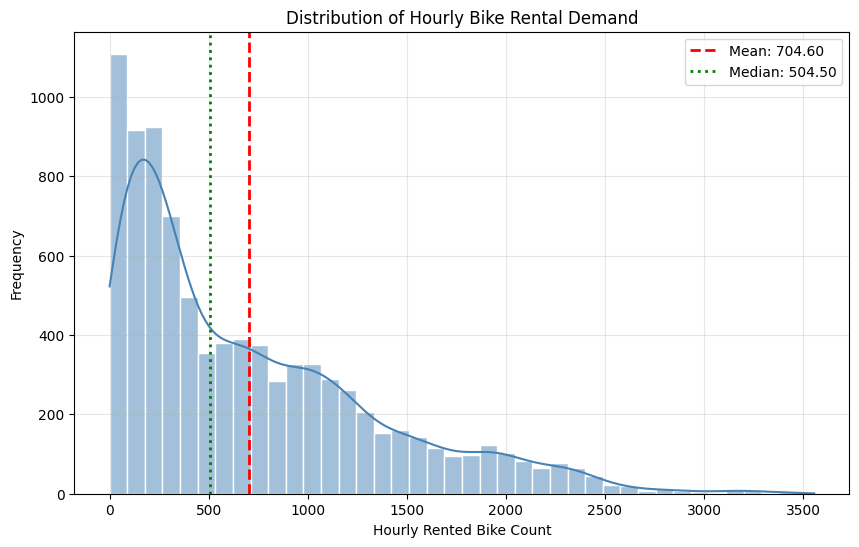

In [15]:
# Distribution Visualization
# Step 1: Calculate mean and median
B1_mean = B1_target.mean()
B1_median = B1_target.median()

# Step 2: Plot target distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    B1_target,
    bins=40,
    kde=True,
    color='steelblue',
    edgecolor='white'
)

# Step 3: Add mean and median reference lines
plt.axvline(
    B1_mean,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean: {B1_mean:.2f}'
)

plt.axvline(
    B1_median,
    color='green',
    linestyle=':',
    linewidth=2,
    label=f'Median: {B1_median:.2f}'
)

# Step 4: Customize the plot
plt.xlabel('Hourly Rented Bike Count')
plt.ylabel('Frequency')
plt.title('Distribution of Hourly Bike Rental Demand')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### B1.1. Potential Outlier Detection

We use the Interquartile Range (IQR) method to identify unusually high or low rental demand.

The IQR is defined as:

$$
IQR = Q_3 - Q_1
$$

Potential outliers are identified using the following boundaries:

$$
Lower = Q_1 - 1.5 \times IQR
$$

$$
Upper = Q_3 + 1.5 \times IQR
$$

Observations outside these boundaries are flagged as potential outliers.

However, unusually high rental counts may represent legitimate peak-demand periods rather than data errors. Therefore, potential outliers will be examined but not automatically removed.

In [16]:
# Step 1: Calculate Q1, Q3, and IQR
B1_Q1 = B1_target.quantile(0.25)
B1_Q3 = B1_target.quantile(0.75)

B1_IQR = B1_Q3 - B1_Q1

# Step 2: Define outlier boundaries
B1_lower_bound = B1_Q1 - 1.5 * B1_IQR
B1_upper_bound = B1_Q3 + 1.5 * B1_IQR

# Step 3: Identify potential outliers
B1_outliers = B1_target[
    (B1_target < B1_lower_bound) |
    (B1_target > B1_upper_bound)
]

# Step 4: Display results
print(f'Q1: {B1_Q1:.2f}')
print(f'Q3: {B1_Q3:.2f}')
print(f'IQR: {B1_IQR:.2f}')
print(f'Lower Bound: {B1_lower_bound:.2f}')
print(f'Upper Bound: {B1_upper_bound:.2f}')

print(f'\nNumber of Potential Outliers: {len(B1_outliers)}')
print(
    f'Percentage of Potential Outliers: '
    f'{len(B1_outliers) / len(B1_target) * 100:.2f}%'
)

Q1: 191.00
Q3: 1065.25
IQR: 874.25
Lower Bound: -1120.38
Upper Bound: 2376.62

Number of Potential Outliers: 158
Percentage of Potential Outliers: 1.80%


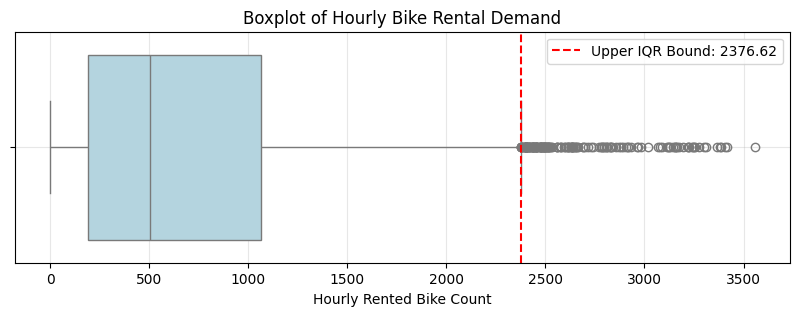

In [17]:
# Boxplot Visualization
# Visualize the target distribution using a boxplot
plt.figure(figsize=(10, 3))

sns.boxplot(
    x=B1_target,
    color='lightblue'
)

plt.axvline(
    B1_upper_bound,
    color='red',
    linestyle='--',
    label=f'Upper IQR Bound: {B1_upper_bound:.2f}'
)

plt.xlabel('Hourly Rented Bike Count')
plt.title('Boxplot of Hourly Bike Rental Demand')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### B1.2. Target Distribution Summary

The hourly bike rental demand exhibits a highly right-skewed distribution, with a skewness coefficient of 1.153.

The mean rental count (704.60) is substantially higher than the median (504.50), indicating that relatively infrequent high-demand observations increase the overall average.

The standard deviation (645.00) is also relatively large compared with the mean, suggesting considerable variability in hourly rental demand.

Using the Interquartile Range (IQR) method, 158 potential outliers (1.80% of all observations) were identified above the upper threshold of 2,376.62 rentals per hour.

These high-demand observations may represent legitimate peak-demand periods rather than measurement errors. Therefore, they are retained for subsequent analysis and modeling.

**Key Takeaways:**

- Rental demand is highly right-skewed (Skewness = 1.153).
- The mean (704.60) exceeds the median (504.50), reflecting the influence of high-demand observations.
- Demand varies considerably, with a standard deviation of 645.00 rentals.
- Only 1.80% of observations exceed the IQR upper threshold.
- High-demand observations are retained to preserve information about potential demand peaks.
- Both MAE and RMSE will be considered during model evaluation to assess typical and large prediction errors.

The next section examines how rental demand varies across hours, weekdays, weekends, and seasons.

## B2. Temporal Demand Analysis

Bike-sharing demand is strongly influenced by temporal factors, particularly commuting patterns and differences between weekdays and weekends.

This section investigates how rental demand varies across different hours and days of the week.

The analysis focuses on:

1. **Hourly Demand Patterns:** Identify peak and off-peak rental hours.
2. **Weekday vs. Weekend Demand:** Compare temporal demand patterns between working days and weekends.
3. **Day-of-Week Analysis:** Examine variations in average rental demand across the seven days of the week.
4. **Hour-Day Interaction:** Visualize how hourly demand patterns vary throughout the week.

These analyses help identify recurring usage patterns that may be useful for feature engineering and demand forecasting.


In [18]:
# Step 1: Calculate hourly rental statistics
B2_hourly_stats = (
    df_clean.groupby('Hour')['Rented_Bike_Count']
    .agg(['mean', 'median', 'std', 'count'])
    .reset_index()
)

# Step 2: Identify peak and off-peak hours
B2_peak_hour = B2_hourly_stats.loc[
    B2_hourly_stats['mean'].idxmax()
]

B2_offpeak_hour = B2_hourly_stats.loc[
    B2_hourly_stats['mean'].idxmin()
]

# Step 3: Display results
display(B2_hourly_stats.round(2))

print(
    f'Peak Hour: {int(B2_peak_hour["Hour"]):02d}:00, '
    f'Average Demand: {B2_peak_hour["mean"]:.2f}'
)

print(
    f'Lowest Demand Hour: {int(B2_offpeak_hour["Hour"]):02d}:00, '
    f'Average Demand: {B2_offpeak_hour["mean"]:.2f}'
)

,Hour,mean,median,std,count
0,0,541.460,513.000,364.570,365
1,1,426.180,401.000,285.530,365
2,2,301.630,265.000,210.110,365
3,3,203.330,176.000,143.200,365
4,4,132.590,119.000,90.270,365
5,5,139.080,129.000,95.520,365
6,6,287.560,232.000,222.820,365
7,7,606.010,426.000,482.260,365
8,8,1015.700,728.000,761.590,365
9,9,645.980,680.000,398.650,365


Peak Hour: 18:00, Average Demand: 1502.93
Lowest Demand Hour: 04:00, Average Demand: 132.59


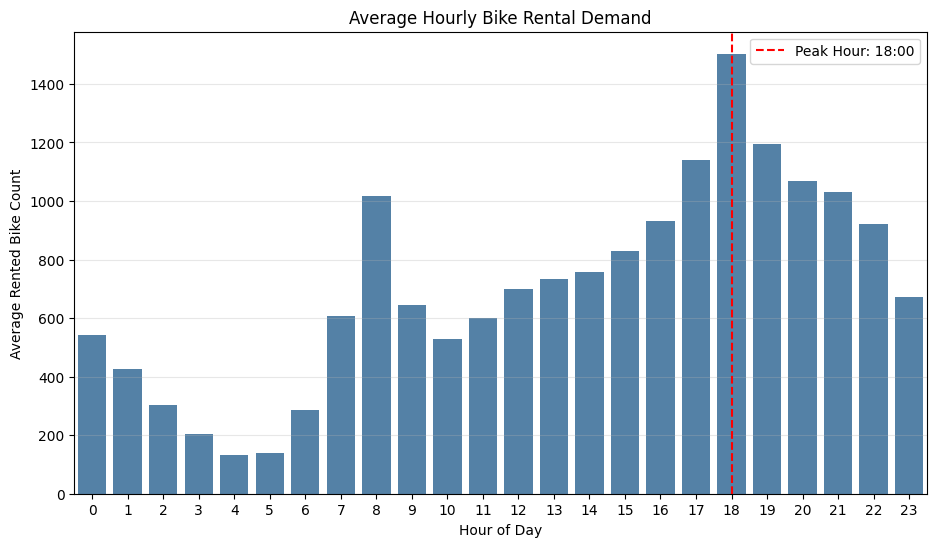

In [19]:
# Step 1: Plot average hourly demand
plt.figure(figsize=(11, 6))

sns.barplot(
    data=B2_hourly_stats,
    x='Hour',
    y='mean',
    color='steelblue'
)

# Step 2: Highlight peak hour
plt.axvline(
    x=B2_peak_hour['Hour'],
    color='red',
    linestyle='--',
    linewidth=1.5,
    label=f'Peak Hour: {int(B2_peak_hour["Hour"]):02d}:00'
)

# Step 3: Customize the plot
plt.xlabel('Hour of Day')
plt.ylabel('Average Rented Bike Count')
plt.title('Average Hourly Bike Rental Demand')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

### B2.1. Weekday vs. Weekend Demand

Bike-sharing behavior may differ between weekdays and weekends.

Weekday demand is expected to exhibit commuting-related peaks during morning and evening hours, whereas weekend demand may be more concentrated during leisure periods.

To investigate these differences, hourly rental demand is grouped by the `Is_Weekend` variable:

- **0:** Weekday (Monday–Friday)
- **1:** Weekend (Saturday–Sunday)

The resulting demand profiles are compared to identify differences in peak hours and daily usage patterns.

In [20]:
# Step 1: Calculate hourly demand by day type
B2_weekend_stats = (
    df_clean.groupby(['Is_Weekend', 'Hour'])['Rented_Bike_Count']
    .agg(['mean', 'median', 'std'])
    .reset_index()
)

# Step 2: Assign readable labels
B2_weekend_stats['Day_Type'] = (
    B2_weekend_stats['Is_Weekend']
    .map({0: 'Weekday', 1: 'Weekend'})
)

# Step 3: Identify peak demand hours
B2_daytype_peaks = (
    B2_weekend_stats.loc[
        B2_weekend_stats.groupby('Day_Type')['mean'].idxmax(),
        ['Day_Type', 'Hour', 'mean']
    ]
    .reset_index(drop=True)
)

display(B2_daytype_peaks.round(2))

,Day_Type,Hour,mean
0,Weekday,18,1658.000
1,Weekend,17,1138.680


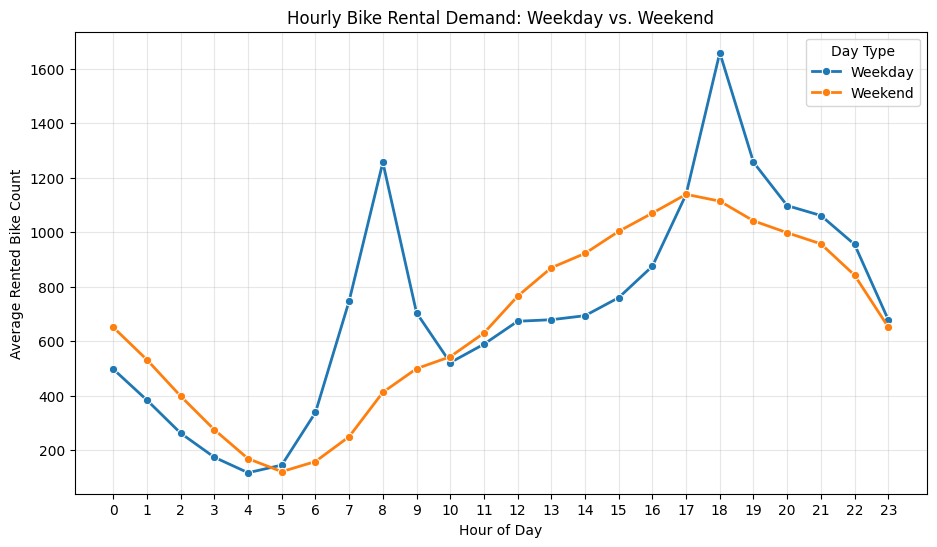

In [21]:
# Plot weekday and weekend hourly demand
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=B2_weekend_stats,
    x='Hour',
    y='mean',
    hue='Day_Type',
    marker='o',
    linewidth=2
)

plt.xlabel('Hour of Day')
plt.ylabel('Average Rented Bike Count')
plt.title('Hourly Bike Rental Demand: Weekday vs. Weekend')
plt.xticks(range(0, 24))
plt.legend(title='Day Type')
plt.grid(True, alpha=0.3)
plt.show()

### B2.2. Day-of-Week Analysis

In addition to hourly demand patterns, rental activity may vary across the seven days of the week.

We calculate the average hourly rental demand for each weekday to investigate whether certain days exhibit consistently higher or lower rental activity.

This analysis provides additional insight into weekly demand patterns and supports the evaluation of `Day_of_Week` as a potential predictive feature.

,mean,median,std
Monday,730.560,533.000,664.960
Tuesday,687.980,485.500,652.170
Wednesday,740.350,536.500,677.570
Thursday,690.700,495.000,641.680
Friday,747.120,566.000,658.400
Saturday,709.530,519.000,603.910
Sunday,625.160,406.000,605.530


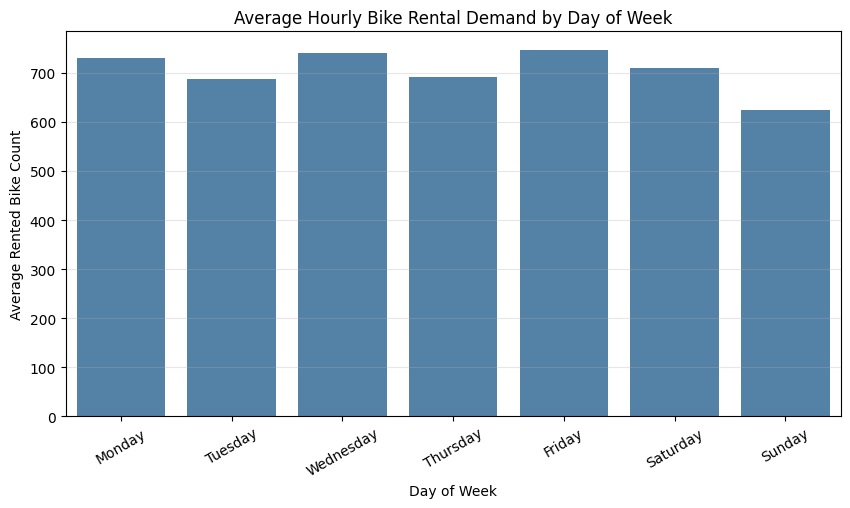

In [22]:
# Step 1: Define day labels
B2_day_names = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

# Step 2: Calculate average rental demand
B2_daily_stats = (
    df_clean.groupby('Day_of_Week')['Rented_Bike_Count']
    .agg(['mean', 'median', 'std'])
    .reindex(range(7))
)

B2_daily_stats.index = B2_day_names

# Step 3: Display results
display(B2_daily_stats.round(2))

# Step 4: Plot average demand
plt.figure(figsize=(10, 5))

sns.barplot(
    x=B2_daily_stats.index,
    y=B2_daily_stats['mean'],
    color='steelblue'
)

plt.xlabel('Day of Week')
plt.ylabel('Average Rented Bike Count')
plt.title('Average Hourly Bike Rental Demand by Day of Week')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.show()

### B2.3. Hour-Day Interaction Analysis

Hourly demand patterns may vary significantly across different days of the week.

To examine this interaction, a pivot table is constructed using:

- **Rows:** Day of Week
- **Columns:** Hour of Day
- **Values:** Mean Rented Bike Count

The resulting matrix is visualized using a heatmap.

This approach highlights recurring demand patterns and provides a more detailed view of temporal interactions than analyzing Hour or Day of Week separately.

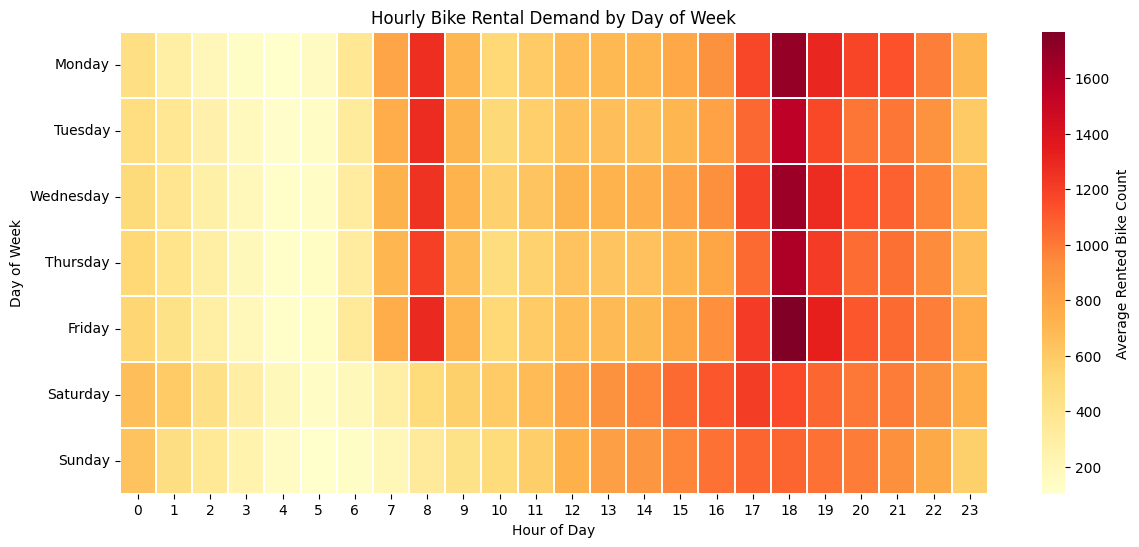

In [23]:
# Step 1: Create the interaction matrix
B2_hour_day_matrix = df_clean.pivot_table(
    index='Day_of_Week',
    columns='Hour',
    values='Rented_Bike_Count',
    aggfunc='mean'
)

# Step 2: Rename day labels
B2_hour_day_matrix.index = B2_day_names

# Step 3: Plot heatmap
plt.figure(figsize=(14, 6))

sns.heatmap(
    B2_hour_day_matrix,
    cmap='YlOrRd',
    linewidths=0.3,
    cbar_kws={'label': 'Average Rented Bike Count'}
)

plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.title('Hourly Bike Rental Demand by Day of Week')
plt.show()

In [24]:
# Step 1: Overall peak and lowest-demand hours
B2_peak_hour_value = int(B2_peak_hour['Hour'])
B2_lowest_hour_value = int(B2_offpeak_hour['Hour'])

# Step 2: Compare average weekday and weekend demand
B2_daytype_summary = (
    df_clean.groupby('Is_Weekend')['Rented_Bike_Count']
    .mean()
)

B2_weekday_mean = B2_daytype_summary.loc[0]
B2_weekend_mean = B2_daytype_summary.loc[1]

B2_weekend_difference = (
    (B2_weekend_mean - B2_weekday_mean)
    / B2_weekday_mean * 100
)

# Step 3: Display quantitative findings
print(f'Overall Peak Hour: {B2_peak_hour_value:02d}:00')
print(f'Lowest Demand Hour: {B2_lowest_hour_value:02d}:00')

print(f'\nWeekday Mean Demand: {B2_weekday_mean:.2f}')
print(f'Weekend Mean Demand: {B2_weekend_mean:.2f}')
print(
    f'Weekend vs. Weekday Difference: '
    f'{B2_weekend_difference:+.2f}%'
)

print('\nPeak Hour by Day Type:')
display(B2_daytype_peaks.round(2))

Overall Peak Hour: 18:00
Lowest Demand Hour: 04:00

Weekday Mean Demand: 719.45
Weekend Mean Demand: 667.34
Weekend vs. Weekday Difference: -7.24%

Peak Hour by Day Type:


,Day_Type,Hour,mean
0,Weekday,18,1658.000
1,Weekend,17,1138.680


### B2.4. Temporal Demand Analysis Summary

The temporal analysis reveals distinct daily and weekly patterns in Seoul's bike-sharing demand.

**1. Hourly Demand Patterns**

The overall hourly demand reaches its peak at 18:00, while the lowest demand occurs at 04:00. A secondary morning peak is also observed around 08:00, suggesting a strong association between bike-sharing activity and commuting hours.

**2. Weekday vs. Weekend Demand**

Weekday demand exhibits two pronounced peaks around 08:00 and 18:00, with the highest average demand reaching 1,658 rentals per hour at 18:00.

In contrast, weekend demand follows a more gradual pattern, increasing throughout the morning and afternoon before reaching its peak of approximately 1,139 rentals per hour at 17:00.

This difference is consistent with commuting-related travel on weekdays and more flexible travel patterns on weekends.

**3. Overall Demand Comparison**

The average hourly rental demand is 719.45 on weekdays and 667.34 on weekends, representing a 7.24% decrease in weekend demand.

Although the difference in overall average demand is relatively modest, the hourly demand profiles differ substantially.

**4. Day-of-Week Interaction**

The interaction heatmap confirms strong morning and evening demand concentrations during weekdays, while weekend demand is distributed more broadly throughout the afternoon and evening.

These findings indicate that the relationship between Hour and rental demand varies depending on the day of the week.

**Key Takeaways:**

- Overall rental demand peaks at 18:00 and reaches its minimum at 04:00.
- Weekday demand displays distinct morning and evening peaks, consistent with commuting activity.
- Weekend demand follows a more gradual pattern, with the highest average demand at 17:00.
- Average hourly demand is 7.24% lower on weekends than on weekdays.
- The interaction between Hour and Day of Week may provide useful predictive information for regression modeling.

These findings support the use of Hour, Day_of_Week, Is_Weekend, and cyclical temporal features in subsequent machine learning models.

## B3. Weather & Seasonal Demand Analysis

Weather conditions and seasonal variations may significantly influence bike-sharing demand.

This section investigates the relationships between rental demand and environmental factors, including temperature, humidity, rainfall, and seasonality.

The analysis focuses on:

1. **Temperature Analysis:** Examine the relationship between temperature and hourly rental demand.
2. **Seasonal Demand Analysis:** Compare rental demand distributions across the four seasons.
3. **Rainfall and Humidity Analysis:** Investigate how precipitation and humidity are associated with bike rental activity.
4. **Correlation Analysis:** Quantify linear associations between rental demand and numerical weather variables.

These analyses help identify potentially important predictors and provide insights into how environmental conditions affect bike-sharing demand.

Temperature vs. Rental Demand Correlation: 0.539


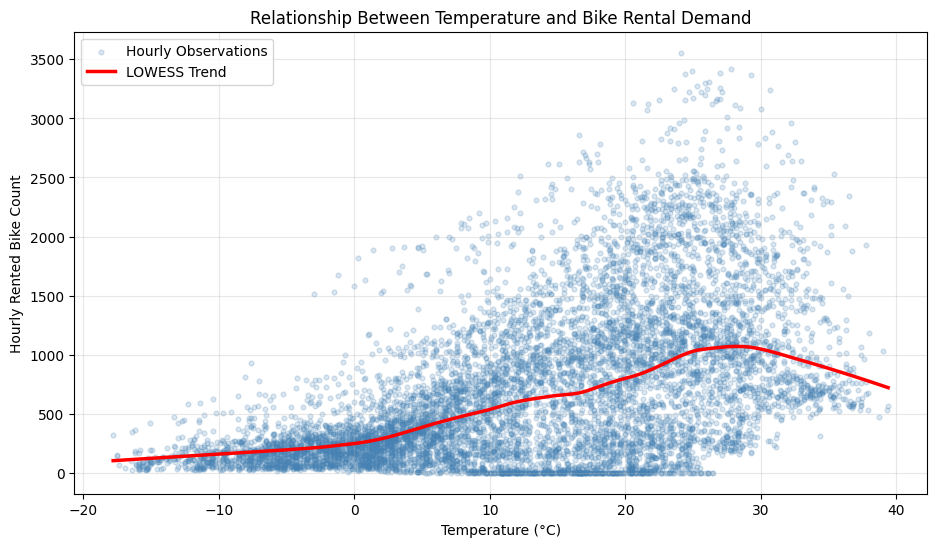

In [25]:
from statsmodels.nonparametric.smoothers_lowess import lowess

# Step 1: Define temperature and rental demand
B3_temperature = df_clean['Temperature']
B3_target = df_clean['Rented_Bike_Count']

# Step 2: Calculate correlation
B3_temp_corr = B3_temperature.corr(B3_target)

print(f'Temperature vs. Rental Demand Correlation: {B3_temp_corr:.3f}')

# Step 3: Calculate LOWESS trend
B3_temp_trend = lowess(
    endog=B3_target,
    exog=B3_temperature,
    frac=0.2,
    return_sorted=True
)

# Step 4: Plot scatter and trend
plt.figure(figsize=(11, 6))

plt.scatter(
    B3_temperature,
    B3_target,
    alpha=0.2,
    s=12,
    color='steelblue',
    label='Hourly Observations'
)

plt.plot(
    B3_temp_trend[:, 0],
    B3_temp_trend[:, 1],
    color='red',
    linewidth=2.5,
    label='LOWESS Trend'
)

plt.xlabel('Temperature (°C)')
plt.ylabel('Hourly Rented Bike Count')
plt.title('Relationship Between Temperature and Bike Rental Demand')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### B3.1. Temperature-Based Demand Comparison

To further investigate the nonlinear relationship between temperature and rental demand, temperature observations are grouped into intervals.

The average rental count is calculated within each interval.

This approach reduces the influence of overlapping observations in the scatter plot and provides a clearer comparison of rental demand across different temperature ranges.

The resulting analysis can help identify temperature ranges associated with relatively high or low bike-sharing demand.

,Temperature_Range,mean,median,count
0,-20 to -10,141.440,109.500,228
1,-10 to 0,210.320,178.000,1226
2,0 to 10,424.700,332.000,2143
3,10 to 20,765.090,716.000,2264
4,20 to 30,1119.990,1058.000,2387
5,30 to 40,1106.400,903.000,512


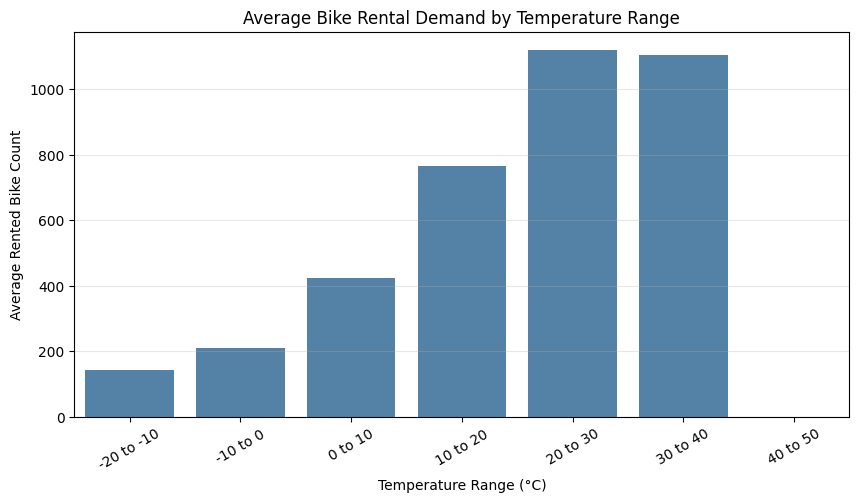

In [26]:
# Step 1: Define temperature intervals
B3_temp_bins = [-20, -10, 0, 10, 20, 30, 40, 50]

B3_temp_labels = [
    '-20 to -10',
    '-10 to 0',
    '0 to 10',
    '10 to 20',
    '20 to 30',
    '30 to 40',
    '40 to 50'
]

# Step 2: Group temperature into intervals
B3_temp_groups = df_clean.copy()

B3_temp_groups['Temperature_Range'] = pd.cut(
    B3_temp_groups['Temperature'],
    bins=B3_temp_bins,
    labels=B3_temp_labels,
    include_lowest=True
)

# Step 3: Calculate average rental demand
B3_temp_stats = (
    B3_temp_groups.groupby(
        'Temperature_Range',
        observed=True
    )['Rented_Bike_Count']
    .agg(['mean', 'median', 'count'])
    .reset_index()
)

# Step 4: Display results
display(B3_temp_stats.round(2))

# Step 5: Plot average demand by temperature range
plt.figure(figsize=(10, 5))

sns.barplot(
    data=B3_temp_stats,
    x='Temperature_Range',
    y='mean',
    color='steelblue'
)

plt.xlabel('Temperature Range (°C)')
plt.ylabel('Average Rented Bike Count')
plt.title('Average Bike Rental Demand by Temperature Range')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.show()

### B3.2. Seasonal Demand Analysis

Bike-sharing demand may vary substantially across seasons due to changes in weather conditions, daylight duration, and travel behavior.

To examine seasonal differences, rental demand is grouped into four categories:

- Winter
- Spring
- Summer
- Autumn

Boxplots are used to compare the median, interquartile range, and distribution of rental demand across seasons.

Additional summary statistics are calculated to quantify differences in average demand and variability.


In [27]:
# Step 1: Define seasonal order
B3_season_order = [
    'Winter', 'Spring', 'Summer', 'Autumn'
]

# Step 2: Calculate seasonal statistics
B3_season_stats = (
    df_clean.groupby('Seasons')['Rented_Bike_Count']
    .agg(['mean', 'median', 'std', 'min', 'max', 'count'])
    .reindex(B3_season_order)
)

# Step 3: Display results
display(B3_season_stats.round(2))

# Step 4: Identify the highest and lowest demand seasons
B3_highest_season = B3_season_stats['mean'].idxmax()
B3_lowest_season = B3_season_stats['mean'].idxmin()

print(
    f'Highest Average Demand Season: {B3_highest_season}'
)

print(
    f'Lowest Average Demand Season: {B3_lowest_season}'
)

,mean,median,std,min,max,count
Seasons,,,,,,
Winter,225.540,203.000,150.370,3,937,2160
Spring,730.030,583.000,621.510,0,3251,2208
Summer,1034.070,905.500,690.240,9,3556,2208
Autumn,819.600,763.500,651.090,0,3298,2184


Highest Average Demand Season: Summer
Lowest Average Demand Season: Winter


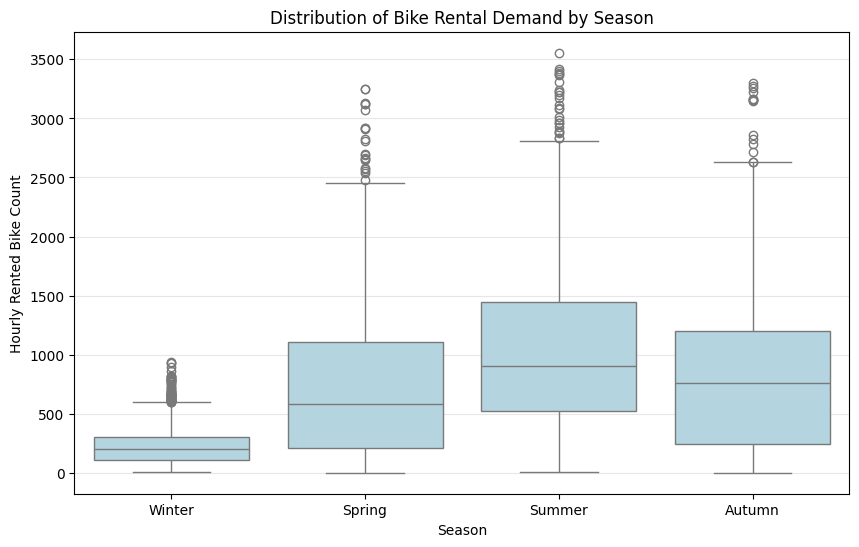

In [28]:
# Plot seasonal rental demand distribution
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x='Seasons',
    y='Rented_Bike_Count',
    order=B3_season_order,
    color='lightblue'
)

plt.xlabel('Season')
plt.ylabel('Hourly Rented Bike Count')
plt.title('Distribution of Bike Rental Demand by Season')
plt.grid(axis='y', alpha=0.3)
plt.show()

### B3.3. Rainfall and Humidity Analysis

Precipitation and humidity may influence the willingness of users to rent bicycles.

To investigate these relationships, we first compare average rental demand between rainy and non-rainy hours.

We then examine how rental demand varies across different humidity levels.

These comparisons provide an initial assessment of whether rainfall and humidity are associated with changes in bike-sharing activity.

However, the analysis remains observational. Differences in rental demand may also be influenced by temperature, seasonality, and time of day.

,mean,median,std,count
Rain_Status,,,,
No Rain,739.310,562.000,646.780,8232
Rain,163.460,67.000,262.070,528


Rain vs. No Rain Difference: -77.89%


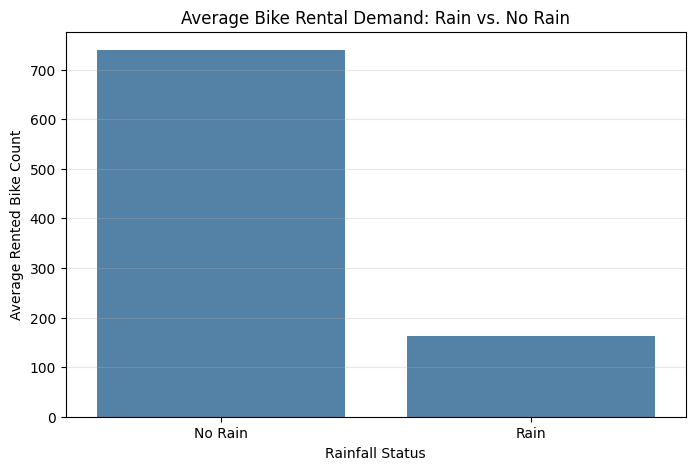

In [29]:
# Step 1: Create rainfall categories
B3_rain_df = df_clean.copy()

B3_rain_df['Rain_Status'] = np.where(
    B3_rain_df['Rainfall'] > 0,
    'Rain',
    'No Rain'
)

# Step 2: Calculate rental statistics
B3_rain_stats = (
    B3_rain_df.groupby('Rain_Status')['Rented_Bike_Count']
    .agg(['mean', 'median', 'std', 'count'])
    .reindex(['No Rain', 'Rain'])
)

# Step 3: Calculate percentage difference
B3_rain_difference = (
    (
        B3_rain_stats.loc['Rain', 'mean']
        - B3_rain_stats.loc['No Rain', 'mean']
    )
    / B3_rain_stats.loc['No Rain', 'mean']
    * 100
)

# Step 4: Display results
display(B3_rain_stats.round(2))

print(
    f'Rain vs. No Rain Difference: '
    f'{B3_rain_difference:+.2f}%'
)

# Step 5: Plot comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    x=B3_rain_stats.index,
    y=B3_rain_stats['mean'],
    color='steelblue'
)

plt.xlabel('Rainfall Status')
plt.ylabel('Average Rented Bike Count')
plt.title('Average Bike Rental Demand: Rain vs. No Rain')
plt.grid(axis='y', alpha=0.3)
plt.show()

,Humidity_Range,mean,median,count
0,"(-0.001, 20.0]",667.700,433.500,142
1,"(20.0, 40.0]",759.740,568.000,1810
2,"(40.0, 60.0]",842.420,704.000,2893
3,"(60.0, 80.0]",725.480,531.000,2399
4,"(80.0, 100.0]",346.180,201.500,1516


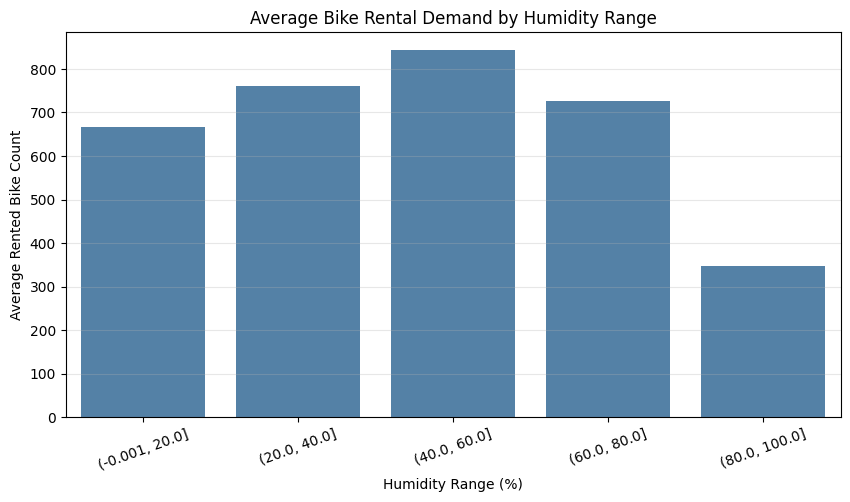

In [30]:
# Step 1: Define humidity intervals
B3_humidity_bins = [0, 20, 40, 60, 80, 100]

# Step 2: Create humidity groups
B3_humidity_df = df_clean.copy()

B3_humidity_df['Humidity_Range'] = pd.cut(
    B3_humidity_df['Humidity'],
    bins=B3_humidity_bins,
    include_lowest=True
)

# Step 3: Calculate statistics
B3_humidity_stats = (
    B3_humidity_df.groupby(
        'Humidity_Range',
        observed=True
    )['Rented_Bike_Count']
    .agg(['mean', 'median', 'count'])
    .reset_index()
)

# Step 4: Display results
display(B3_humidity_stats.round(2))

# Step 5: Plot average demand by humidity range
plt.figure(figsize=(10, 5))

sns.barplot(
    data=B3_humidity_stats,
    x='Humidity_Range',
    y='mean',
    color='steelblue'
)

plt.xlabel('Humidity Range (%)')
plt.ylabel('Average Rented Bike Count')
plt.title('Average Bike Rental Demand by Humidity Range')
plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)
plt.show()

### B3.4. Weather Feature Correlation Analysis

Correlation analysis is used to quantify linear relationships between numerical weather variables and rental demand.

The Pearson correlation coefficient ranges from -1 to 1:

- **Positive Correlation:** Higher feature values tend to be associated with higher rental demand.
- **Negative Correlation:** Higher feature values tend to be associated with lower rental demand.
- **Near-Zero Correlation:** Indicates a weak linear relationship, but does not necessarily imply that no relationship exists.

A correlation matrix is calculated and visualized using a heatmap.

Because Pearson correlation measures linear association, nonlinear relationships may not be fully represented by the correlation coefficients.

Correlation with Rented Bike Count:


,Rented_Bike_Count
Temperature,0.539
Dew_Point_Temp,0.380
Solar_Radiation,0.262
Visibility,0.199
Wind_Speed,0.121
Rainfall,-0.123
Snowfall,-0.142
Humidity,-0.200


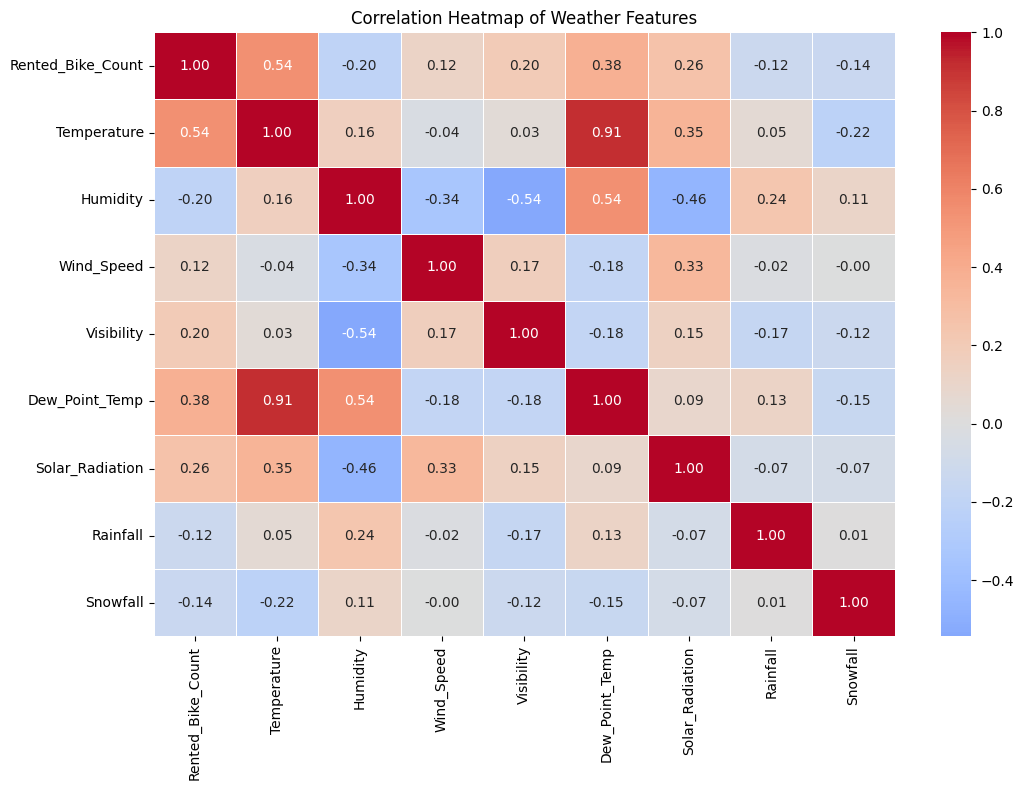

In [31]:
# Step 1: Select numerical weather features
B3_weather_features = [
    'Rented_Bike_Count',
    'Temperature',
    'Humidity',
    'Wind_Speed',
    'Visibility',
    'Dew_Point_Temp',
    'Solar_Radiation',
    'Rainfall',
    'Snowfall'
]

# Step 2: Calculate Pearson correlation matrix
B3_corr_matrix = df_clean[B3_weather_features].corr()

# Step 3: Display correlations with target
B3_target_corr = (
    B3_corr_matrix['Rented_Bike_Count']
    .drop('Rented_Bike_Count')
    .sort_values(ascending=False)
)

print('Correlation with Rented Bike Count:')
display(B3_target_corr.round(3))

# Step 4: Plot correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    B3_corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Correlation Heatmap of Weather Features')
plt.tight_layout()
plt.show()

In [32]:
# Step 1: Identify highest-demand temperature interval
B3_best_temp_index = B3_temp_stats['mean'].idxmax()

B3_best_temp_range = B3_temp_stats.loc[
    B3_best_temp_index, 'Temperature_Range'
]

B3_best_temp_mean = B3_temp_stats.loc[
    B3_best_temp_index, 'mean'
]

# Step 2: Identify strongest absolute weather correlation
B3_strongest_feature = B3_target_corr.abs().idxmax()
B3_strongest_corr = B3_target_corr.loc[
    B3_strongest_feature
]

# Step 3: Display key findings
print(
    f'Temperature Correlation: {B3_temp_corr:.3f}'
)

print(
    f'Highest Demand Temperature Range: '
    f'{B3_best_temp_range}'
)

print(
    f'Average Demand in Range: '
    f'{B3_best_temp_mean:.2f}'
)

print(
    f'Highest Average Demand Season: '
    f'{B3_highest_season}'
)

print(
    f'Lowest Average Demand Season: '
    f'{B3_lowest_season}'
)

print(
    f'Rain vs. No Rain Difference: '
    f'{B3_rain_difference:+.2f}%'
)

print(
    f'Strongest Absolute Weather Correlation: '
    f'{B3_strongest_feature} '
    f'(r = {B3_strongest_corr:.3f})'
)

Temperature Correlation: 0.539
Highest Demand Temperature Range: 20 to 30
Average Demand in Range: 1119.99
Highest Average Demand Season: Summer
Lowest Average Demand Season: Winter
Rain vs. No Rain Difference: -77.89%
Strongest Absolute Weather Correlation: Temperature (r = 0.539)


### B3.5. Weather & Seasonal Demand Analysis Summary

The analysis reveals substantial associations between weather conditions, seasonality, and hourly bike rental demand.

**1. Temperature**

Temperature exhibits the strongest positive linear correlation with rental demand among the weather variables (Pearson r = 0.539).

The LOWESS trend also suggests a nonlinear relationship, with rental demand generally increasing under warmer conditions before declining at higher temperatures.

The highest average rental demand (1,119.99) occurs within the 20–30°C temperature interval.

**2. Seasonality**

Summer has the highest average hourly rental demand (1,034.07), while Winter has the lowest (225.54).

Average summer demand is approximately 4.59 times winter demand, indicating substantial seasonal variation.

**3. Rainfall and Humidity**

Average rental demand during rainy hours (163.46) is 77.89% lower than during non-rainy hours (739.31).

However, continuous rainfall exhibits only a weak negative Pearson correlation with demand (r = -0.123), suggesting that the presence of rainfall and its intensity may capture different aspects of demand behavior.

Humidity also exhibits a weak negative linear correlation (r = -0.200), although grouped analysis reveals a nonlinear pattern across humidity intervals.

**4. Feature Correlation and Multicollinearity**

Temperature and Dew Point Temperature exhibit a strong positive correlation (r = 0.91), indicating potential multicollinearity among weather predictors.

This relationship may affect the interpretation and stability of linear regression coefficients.

**Key Takeaways:**

- Temperature has the strongest observed linear association with rental demand among weather variables.
- Temperature-demand relationships show evidence of nonlinearity.
- Summer demand is approximately 4.59 times winter demand.
- Rainy hours exhibit substantially lower average rental demand than non-rainy hours.
- Strong correlations among weather predictors should be considered when interpreting regression models.
- Correlation does not necessarily imply causation or predictive importance.

These findings support the inclusion of weather and seasonal variables in subsequent regression modeling and motivate further investigation using nonlinear models and feature importance analysis.

# Part C: Regression Modeling

## C1. Data Splitting & Baseline Linear Regression

Following data preprocessing and exploratory analysis, we develop regression models to predict hourly bike rental demand.

Linear Regression is selected as the baseline model due to its simplicity, computational efficiency, and interpretability.

The modeling workflow includes:

1. **Feature Selection:** Identify numerical and categorical predictors.
2. **Train-Test Split:** Divide the dataset into training and testing sets.
3. **Preprocessing Pipeline:** Apply feature scaling and categorical encoding without data leakage.
4. **Model Training:** Fit a Linear Regression model using the training data.
5. **Performance Evaluation:** Evaluate predictions using MAE, RMSE, and R².

Since the dataset contains chronological observations, we use a time-based train-test split rather than random sampling.

The earliest 80% of dates are used for training, while the latest 20% are reserved for testing.

This approach provides a more realistic assessment of model performance on future observations.

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Step 1: Define target variable
C1_target = 'Rented_Bike_Count'

# Step 2: Define numerical features
C1_numeric_features = [
    'Temperature',
    'Humidity',
    'Wind_Speed',
    'Visibility',
    'Dew_Point_Temp',
    'Solar_Radiation',
    'Rainfall',
    'Snowfall',
    'Hour_sin',
    'Hour_cos',
    'Month_sin',
    'Month_cos',
    'Holiday',
    'Functioning_Day'
]

# Step 3: Define categorical features
C1_categorical_features = [
    'Seasons',
    'Day_of_Week'
]

# Step 4: Combine selected features
C1_features = (
    C1_numeric_features +
    C1_categorical_features
)

# Step 5: Define X and y
X = df_clean[C1_features].copy()
y = df_clean[C1_target].copy()

print(f'Number of Features: {X.shape[1]}')
print(f'Number of Observations: {X.shape[0]}')

print('\nNumerical Features:')
print(C1_numeric_features)

print('\nCategorical Features:')
print(C1_categorical_features)

Number of Features: 16
Number of Observations: 8760

Numerical Features:
['Temperature', 'Humidity', 'Wind_Speed', 'Visibility', 'Dew_Point_Temp', 'Solar_Radiation', 'Rainfall', 'Snowfall', 'Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'Holiday', 'Functioning_Day']

Categorical Features:
['Seasons', 'Day_of_Week']


### C1.1. Time-Based Train-Test Split

A conventional random train-test split may distribute observations from the same time period across both training and testing datasets.

Since bike rental demand exhibits temporal patterns, we use a chronological split to evaluate performance on later observations.

The dataset is divided as follows:

- **Training Set:** Earliest 80% of dates.
- **Testing Set:** Latest 20% of dates.

All observations from a given date remain in the same subset.

This reduces temporal overlap between training and testing periods and provides a more realistic evaluation of future demand prediction.

The test set will remain separate from subsequent hyperparameter tuning and model selection.

In [34]:
# Step 1: Sort the dataset chronologically
C1_sorted_df = (
    df_clean
    .sort_values(['Date', 'Hour'])
    .reset_index(drop=True)
)

# Step 2: Determine the training cutoff date
C1_dates = np.sort(C1_sorted_df['Date'].unique())

C1_split_index = int(len(C1_dates) * 0.8)
C1_cutoff_date = C1_dates[C1_split_index]

# Step 3: Define train and test masks
C1_train_mask = C1_sorted_df['Date'] < C1_cutoff_date
C1_test_mask = ~C1_train_mask

# Step 4: Split features and target
X_train = C1_sorted_df.loc[
    C1_train_mask, C1_features
].copy()

X_test = C1_sorted_df.loc[
    C1_test_mask, C1_features
].copy()

y_train = C1_sorted_df.loc[
    C1_train_mask, C1_target
].copy()

y_test = C1_sorted_df.loc[
    C1_test_mask, C1_target
].copy()

# Step 5: Display split information
print(f'Training Samples: {len(X_train)}')
print(f'Testing Samples: {len(X_test)}')

print(
    f'Training Period: '
    f'{C1_sorted_df.loc[C1_train_mask, "Date"].min().date()} '
    f'to {C1_sorted_df.loc[C1_train_mask, "Date"].max().date()}'
)

print(
    f'Testing Period: '
    f'{C1_sorted_df.loc[C1_test_mask, "Date"].min().date()} '
    f'to {C1_sorted_df.loc[C1_test_mask, "Date"].max().date()}'
)

print(
    f'Training Percentage: '
    f'{len(X_train) / len(C1_sorted_df) * 100:.2f}%'
)

print(
    f'Testing Percentage: '
    f'{len(X_test) / len(C1_sorted_df) * 100:.2f}%'
)

# Verify chronological separation
assert (
    C1_sorted_df.loc[C1_train_mask, 'Date'].max()
    <
    C1_sorted_df.loc[C1_test_mask, 'Date'].min()
)

Training Samples: 7008
Testing Samples: 1752
Training Period: 2017-12-01 to 2018-09-18
Testing Period: 2018-09-19 to 2018-11-30
Training Percentage: 80.00%
Testing Percentage: 20.00%


### C1.2. Preprocessing Pipeline

Numerical and categorical features require different preprocessing approaches.

**Numerical Features**

StandardScaler is applied to standardize numerical features:

$$
z = \frac{x-\mu}{\sigma}
$$

where the mean and standard deviation are estimated from the training data.

**Categorical Features**

OneHotEncoder is applied to Seasons and Day_of_Week to convert categorical variables into numerical indicators.

A ColumnTransformer is used to combine these preprocessing operations.

The preprocessing steps are integrated with Linear Regression using a Scikit-learn Pipeline.

This ensures that preprocessing parameters are learned from the training dataset only, reducing the risk of data leakage.

In [35]:
# Step 1: Define numerical preprocessing
C1_numeric_transformer = StandardScaler()

# Step 2: Define categorical preprocessing
C1_categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Step 3: Combine preprocessing steps
C1_preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            C1_numeric_transformer,
            C1_numeric_features
        ),
        (
            'cat',
            C1_categorical_transformer,
            C1_categorical_features
        )
    ]
)

# Step 4: Build Linear Regression pipeline
C1_model = Pipeline(
    steps=[
        ('preprocessor', C1_preprocessor),
        ('regressor', LinearRegression())
    ]
)

# Display pipeline
C1_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Temperature', 'Humidity',
                                                   'Wind_Speed', 'Visibility',
                                                   'Dew_Point_Temp',
                                                   'Solar_Radiation',
                                                   'Rainfall', 'Snowfall',
                                                   'Hour_sin', 'Hour_cos',
                                                   'Month_sin', 'Month_cos',
                                                   'Holiday',
                                                   'Functioning_Day']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Seasons',
                                                   'Day_of_Week'])])),
                ('regressor', LinearRegression())])

In [36]:
# Step 1: Train the Linear Regression model
C1_model.fit(X_train, y_train)

# Step 2: Generate predictions
C1_y_train_pred = C1_model.predict(X_train)
C1_y_test_pred = C1_model.predict(X_test)

print('Linear Regression training completed.')
print(f'Training Predictions: {len(C1_y_train_pred)}')
print(f'Testing Predictions: {len(C1_y_test_pred)}')

Linear Regression training completed.
Training Predictions: 7008
Testing Predictions: 1752


### C1.3. Baseline Model Evaluation

The Linear Regression model is evaluated using three regression metrics:

**Mean Absolute Error (MAE)**

Measures the average absolute difference between actual and predicted rental counts.

**Root Mean Squared Error (RMSE)**

Measures the square root of the average squared prediction error, placing greater emphasis on large errors.

**Coefficient of Determination (R²)**

Measures the model's predictive performance relative to predicting the mean of the evaluation dataset.

For MAE and RMSE, lower values indicate better performance. For R², higher values generally indicate better performance, with 1 representing a perfect fit.

Both training and testing metrics are calculated to examine potential generalization gaps.

In [37]:
# Step 1: Define evaluation function
def C1_evaluate_regression(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    }

# Step 2: Evaluate training and testing performance
C1_train_metrics = C1_evaluate_regression(
    y_train, C1_y_train_pred
)

C1_test_metrics = C1_evaluate_regression(
    y_test, C1_y_test_pred
)

# Step 3: Create comparison table
C1_results = pd.DataFrame(
    [C1_train_metrics, C1_test_metrics],
    index=['Training', 'Testing']
)

# Step 4: Display results
display(C1_results.round(4))

print('Baseline Linear Regression Performance:')
print(f'Test MAE:  {C1_test_metrics["MAE"]:.4f}')
print(f'Test RMSE: {C1_test_metrics["RMSE"]:.4f}')
print(f'Test R²:   {C1_test_metrics["R2"]:.4f}')

,MAE,RMSE,R2
Training,322.837,427.857,0.569
Testing,306.478,426.215,0.517


Baseline Linear Regression Performance:
Test MAE:  306.4775
Test RMSE: 426.2150
Test R²:   0.5171


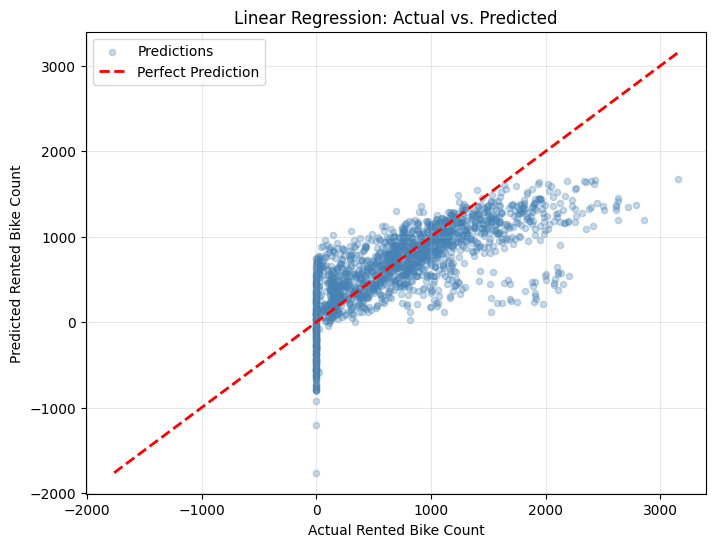

In [38]:
# Actual vs. Predicted Visualization
# Step 1: Define plot limits
C1_plot_min = min(y_test.min(), C1_y_test_pred.min())
C1_plot_max = max(y_test.max(), C1_y_test_pred.max())

# Step 2: Plot actual vs. predicted
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    C1_y_test_pred,
    alpha=0.3,
    s=20,
    color='steelblue',
    label='Predictions'
)

# Step 3: Add ideal prediction line
plt.plot(
    [C1_plot_min, C1_plot_max],
    [C1_plot_min, C1_plot_max],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Perfect Prediction'
)

plt.xlabel('Actual Rented Bike Count')
plt.ylabel('Predicted Rented Bike Count')
plt.title('Linear Regression: Actual vs. Predicted')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [39]:
# Prediction Diagnostics
# Step 1: Count negative predictions
C1_negative_count = np.sum(C1_y_test_pred < 0)

C1_negative_pct = (
    C1_negative_count / len(C1_y_test_pred) * 100
)

# Step 2: Evaluate zero-demand observations
C1_zero_mask = (y_test == 0).to_numpy()

C1_zero_count = C1_zero_mask.sum()

C1_zero_mae = mean_absolute_error(
    y_test.to_numpy()[C1_zero_mask],
    C1_y_test_pred[C1_zero_mask]
) if C1_zero_count > 0 else np.nan

# Step 3: Display diagnostic results
print(f'Negative Predictions: {C1_negative_count}')
print(f'Negative Prediction Percentage: {C1_negative_pct:.2f}%')

print(f'\nZero-Demand Observations: {C1_zero_count}')
print(f'MAE on Zero-Demand Observations: {C1_zero_mae:.2f}')

Negative Predictions: 135
Negative Prediction Percentage: 7.71%

Zero-Demand Observations: 223
MAE on Zero-Demand Observations: 341.42


In [40]:
# Analyze zero-demand observations by operational status
C1_zero_status = pd.DataFrame({
    'Actual': y_test.to_numpy(),
    'Predicted': C1_y_test_pred,
    'Functioning_Day': X_test['Functioning_Day'].to_numpy()
})

display(
    C1_zero_status.loc[
        C1_zero_status['Actual'] == 0,
        'Functioning_Day'
    ].value_counts()
)

,count
Functioning_Day,
0,223


### C1.4. Baseline Linear Regression Summary

A baseline Linear Regression model was developed to predict hourly bike rental demand using weather, temporal, seasonal, and operational features.

The dataset was divided chronologically, with the earliest 80% of dates used for training and the latest 20% reserved for testing. Numerical features were standardized using StandardScaler, while categorical features were encoded using OneHotEncoder. These preprocessing steps were integrated into a Scikit-learn Pipeline to prevent preprocessing leakage.

**1. Model Performance**

The Linear Regression model achieved the following results on the held-out testing dataset:

| Metric | Test Result |
|---|---|
| Mean Absolute Error (MAE) | 306.48 |
| Root Mean Squared Error (RMSE) | 426.22 |
| R² Score | 0.5171 |

The model explains approximately 51.71% of the variance in hourly rental demand. The RMSE is considerably higher than the MAE, indicating the presence of relatively large prediction errors.

**2. Prediction Performance and Limitations**

The Actual vs. Predicted scatter plot reveals several limitations:

- **High-Demand Underestimation:** The model frequently underestimates high rental counts, indicating difficulty capturing peak-demand conditions.
- **Negative Predictions:** A total of 135 predictions (7.71% of the testing observations) are negative, which is inconsistent with the non-negative nature of rental counts.
- **Limited Predictive Flexibility:** The model cannot fully capture the nonlinear relationships and interactions among weather conditions, temporal patterns, and operational status.

These findings suggest that a simple additive linear model may not adequately represent the complexity of bike-sharing demand.

**3. Zero-Demand and Operational Status Analysis**

Further diagnostic analysis identified 223 zero-demand observations in the testing dataset.

All 223 observations occurred during non-operational periods (`Functioning_Day = 0`), confirming that zero rental counts in the testing dataset were associated with service unavailability.

The baseline model achieved an MAE of 341.42 on these zero-demand observations, exceeding the overall testing MAE of 306.48.

Although Functioning_Day was included as a predictor, the Linear Regression model did not fully enforce the operational constraint that rental demand must be zero when the system is not functioning.

This highlights an opportunity to incorporate domain-specific business rules into the prediction process.

**4. Potential Model Improvements**

Several approaches may improve predictive performance:

- **Nonlinear Regression:** Random Forest Regressor may better capture nonlinear relationships and feature interactions.
- **Operational Constraints:** When future operational status is known, predictions can be explicitly set to zero during non-operational periods.
- **Model Diagnostics:** Further evaluation of high-demand and zero-demand observations can help identify conditions associated with larger prediction errors.
- **Model Optimization:** Cross-validation and hyperparameter tuning can be used to improve generalization performance.

**Key Takeaways:**

- Linear Regression provides an interpretable baseline, achieving a test R² of 0.5171.
- The model exhibits substantial prediction errors, particularly during high-demand and zero-demand conditions.
- Negative predictions account for 7.71% of the testing observations.
- All 223 zero-demand testing observations occurred during non-operational periods.
- The zero-demand MAE of 341.42 demonstrates the limitations of an unconstrained linear model.
- Integrating operational rules may improve prediction consistency and practical applicability.
- More flexible nonlinear models should be evaluated to determine whether predictive performance can be improved.

The next section develops a Random Forest Regressor using the same training and testing datasets, allowing a consistent comparison with the Linear Regression baseline.

## C2. Random Forest Regression

The baseline Linear Regression model achieved a test R² of 0.5171 but showed limitations in predicting peak rental demand and non-operational periods.

To address potential nonlinear relationships and feature interactions, we introduce a Random Forest Regressor.

Random Forest is an ensemble learning algorithm that combines multiple decision trees using Bootstrap Aggregating (Bagging). Each tree learns patterns from a random sample of the training data, and the final regression prediction is obtained by averaging the predictions of individual trees.

Compared with Linear Regression, Random Forest can capture nonlinear relationships and complex interactions without explicitly defining interaction terms.

This section focuses on:

1. **Model Training:** Train a baseline Random Forest Regressor.
2. **Performance Evaluation:** Calculate MAE, RMSE, and R².
3. **Model Comparison:** Compare Random Forest with Linear Regression.
4. **Prediction Diagnostics:** Evaluate high-demand and zero-demand observations.
5. **Generalization Assessment:** Compare training and testing performance to identify potential overfitting.

Hyperparameter optimization will be conducted separately in Part D.

In [41]:
from sklearn.base import clone

# Step 1: Build Random Forest pipeline
C2_model = Pipeline(
    steps=[
        ('preprocessor', clone(C1_preprocessor)),
        ('regressor', RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Step 2: Train the model
C2_model.fit(X_train, y_train)

# Step 3: Generate predictions
C2_y_train_pred = C2_model.predict(X_train)
C2_y_test_pred = C2_model.predict(X_test)

print('Random Forest training completed.')
print(f'Number of Trees: 100')
print(f'Training Predictions: {len(C2_y_train_pred)}')
print(f'Testing Predictions: {len(C2_y_test_pred)}')

Random Forest training completed.
Number of Trees: 100
Training Predictions: 7008
Testing Predictions: 1752


### C2.1. Random Forest Performance Evaluation

The Random Forest Regressor is evaluated using the same performance metrics as the Linear Regression baseline:

- **Mean Absolute Error (MAE):** Measures the average absolute prediction error.
- **Root Mean Squared Error (RMSE):** Penalizes large prediction errors more heavily.
- **R² Score:** Measures predictive performance relative to the mean prediction baseline.

Both training and testing performance are evaluated.

A substantial difference between training and testing performance may indicate overfitting, particularly if the model performs extremely well on training observations but generalizes poorly to unseen data.

In [42]:
# Step 1: Evaluate training performance
C2_train_metrics = C1_evaluate_regression(
    y_train, C2_y_train_pred
)

# Step 2: Evaluate testing performance
C2_test_metrics = C1_evaluate_regression(
    y_test, C2_y_test_pred
)

# Step 3: Create results table
C2_results = pd.DataFrame(
    [C2_train_metrics, C2_test_metrics],
    index=['Training', 'Testing']
)

# Step 4: Display results
display(C2_results.round(4))

print('Random Forest Performance:')
print(f'Test MAE:  {C2_test_metrics["MAE"]:.4f}')
print(f'Test RMSE: {C2_test_metrics["RMSE"]:.4f}')
print(f'Test R²:   {C2_test_metrics["R2"]:.4f}')

,MAE,RMSE,R2
Training,37.425,67.203,0.989
Testing,264.164,361.818,0.652


Random Forest Performance:
Test MAE:  264.1643
Test RMSE: 361.8183
Test R²:   0.6520


In [43]:
# Model Comparison
# Step 1: Collect testing results
C2_comparison = pd.DataFrame(
    {
        'Linear Regression': C1_test_metrics,
        'Random Forest': C2_test_metrics
    }
).T

# Step 2: Calculate improvement
C2_mae_improvement = (
    (C1_test_metrics['MAE'] - C2_test_metrics['MAE'])
    / C1_test_metrics['MAE'] * 100
)

C2_rmse_improvement = (
    (C1_test_metrics['RMSE'] - C2_test_metrics['RMSE'])
    / C1_test_metrics['RMSE'] * 100
)

C2_r2_improvement = (
    C2_test_metrics['R2'] - C1_test_metrics['R2']
)

# Step 3: Display comparison
display(C2_comparison.round(4))

print(
    f'MAE Reduction: {C2_mae_improvement:+.2f}%'
)

print(
    f'RMSE Reduction: {C2_rmse_improvement:+.2f}%'
)

print(
    f'R² Improvement: {C2_r2_improvement:+.4f}'
)

,MAE,RMSE,R2
Linear Regression,306.478,426.215,0.517
Random Forest,264.164,361.818,0.652


MAE Reduction: +13.81%
RMSE Reduction: +15.11%
R² Improvement: +0.1349


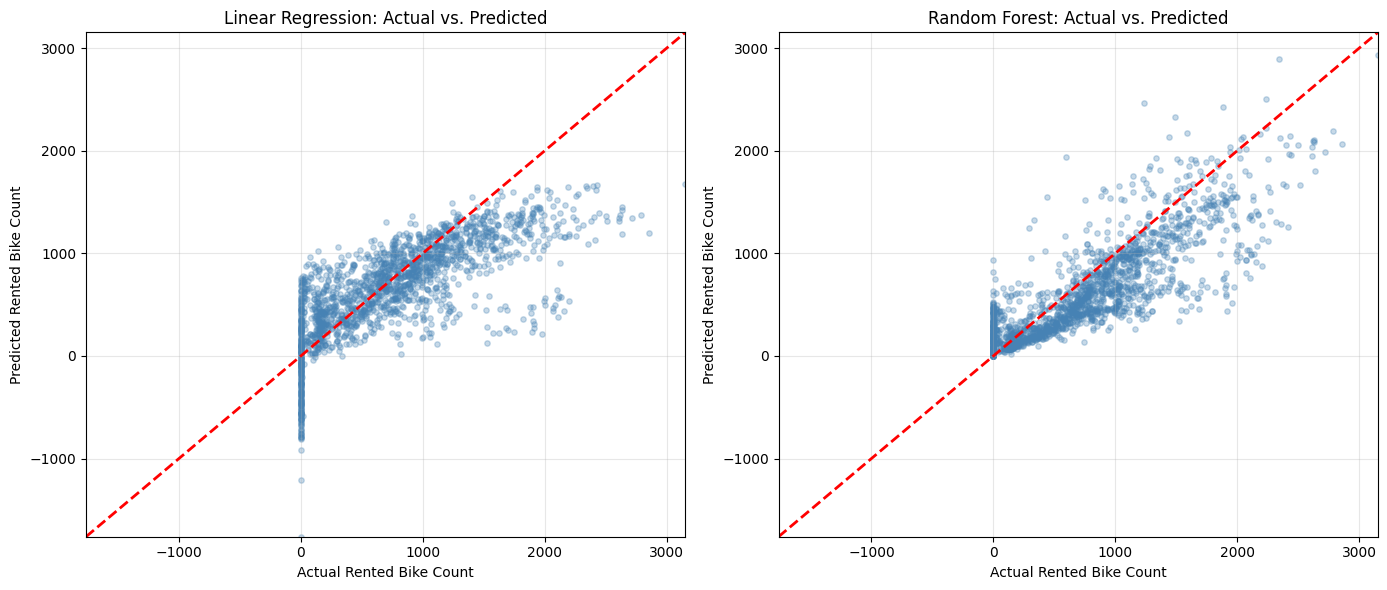

In [44]:
# Actual vs. Predicted Comparison
# Step 1: Define common plot limits
C2_plot_min = min(
    y_test.min(),
    C1_y_test_pred.min(),
    C2_y_test_pred.min()
)

C2_plot_max = max(
    y_test.max(),
    C1_y_test_pred.max(),
    C2_y_test_pred.max()
)

# Step 2: Create comparison plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

C2_models = [
    ('Linear Regression', C1_y_test_pred),
    ('Random Forest', C2_y_test_pred)
]

for ax, (name, y_pred) in zip(axes, C2_models):
    ax.scatter(
        y_test,
        y_pred,
        alpha=0.3,
        s=15,
        color='steelblue'
    )

    ax.plot(
        [C2_plot_min, C2_plot_max],
        [C2_plot_min, C2_plot_max],
        color='red',
        linestyle='--',
        linewidth=2
    )

    ax.set_title(f'{name}: Actual vs. Predicted')
    ax.set_xlabel('Actual Rented Bike Count')
    ax.set_ylabel('Predicted Rented Bike Count')
    ax.set_xlim(C2_plot_min, C2_plot_max)
    ax.set_ylim(C2_plot_min, C2_plot_max)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### C2.2. Prediction Diagnostics

In addition to overall performance metrics, we examine model behavior under specific demand conditions.

The previous Linear Regression analysis identified two important challenges:

1. **High-Demand Observations:** Large rental counts were frequently underestimated.
2. **Zero-Demand Observations:** All 223 zero-demand testing observations occurred during non-operational periods.

To investigate whether Random Forest addresses these limitations, we compare prediction errors across different demand conditions.

High-demand observations are defined using the IQR upper threshold calculated in Part B1.

Zero-demand observations are analyzed separately to evaluate the model's ability to recognize non-operational periods.

In [45]:
# Step 1: Identify high-demand testing observations
C2_high_mask = (y_test > B1_upper_bound).to_numpy()

C2_high_count = C2_high_mask.sum()

# Step 2: Calculate MAE for high-demand observations
if C2_high_count > 0:
    C2_high_mae_lr = mean_absolute_error(
        y_test.to_numpy()[C2_high_mask],
        C1_y_test_pred[C2_high_mask]
    )

    C2_high_mae_rf = mean_absolute_error(
        y_test.to_numpy()[C2_high_mask],
        C2_y_test_pred[C2_high_mask]
    )
else:
    C2_high_mae_lr = np.nan
    C2_high_mae_rf = np.nan

# Step 3: Display results
print(f'High-Demand Threshold: {B1_upper_bound:.2f}')
print(f'High-Demand Test Observations: {C2_high_count}')

print(f'\nLinear Regression High-Demand MAE: {C2_high_mae_lr:.2f}')
print(f'Random Forest High-Demand MAE: {C2_high_mae_rf:.2f}')

High-Demand Threshold: 2376.62
High-Demand Test Observations: 19

Linear Regression High-Demand MAE: 1193.33
Random Forest High-Demand MAE: 603.85


In [46]:
# Step 1: Identify zero-demand observations
C2_zero_mask = (y_test == 0).to_numpy()

C2_zero_count = C2_zero_mask.sum()

# Step 2: Calculate MAE on zero-demand observations
C2_zero_mae_lr = mean_absolute_error(
    y_test.to_numpy()[C2_zero_mask],
    C1_y_test_pred[C2_zero_mask]
) if C2_zero_count > 0 else np.nan

C2_zero_mae_rf = mean_absolute_error(
    y_test.to_numpy()[C2_zero_mask],
    C2_y_test_pred[C2_zero_mask]
) if C2_zero_count > 0 else np.nan

# Step 3: Check negative predictions
C2_negative_count = np.sum(C2_y_test_pred < 0)

# Step 4: Display results
print(f'Zero-Demand Test Observations: {C2_zero_count}')

print(f'\nLinear Regression Zero-Demand MAE: {C2_zero_mae_lr:.2f}')
print(f'Random Forest Zero-Demand MAE: {C2_zero_mae_rf:.2f}')

print(f'\nRandom Forest Negative Predictions: {C2_negative_count}')

Zero-Demand Test Observations: 223

Linear Regression Zero-Demand MAE: 341.42
Random Forest Zero-Demand MAE: 174.74

Random Forest Negative Predictions: 0


In [47]:
# Detailed Diagnostic Comparison
# Step 1: Define diagnostic categories
C2_diagnostic_results = pd.DataFrame({
    'Demand Category': [
        'Overall',
        'High Demand',
        'Zero Demand'
    ],
    'Observations': [
        len(y_test),
        C2_high_count,
        C2_zero_count
    ],
    'Linear Regression MAE': [
        C1_test_metrics['MAE'],
        C2_high_mae_lr,
        C2_zero_mae_lr
    ],
    'Random Forest MAE': [
        C2_test_metrics['MAE'],
        C2_high_mae_rf,
        C2_zero_mae_rf
    ]
})

# Step 2: Calculate percentage improvement
C2_diagnostic_results['MAE Reduction (%)'] = (
    (
        C2_diagnostic_results['Linear Regression MAE']
        - C2_diagnostic_results['Random Forest MAE']
    )
    / C2_diagnostic_results['Linear Regression MAE']
    * 100
)

# Step 3: Display results
display(C2_diagnostic_results.round(2))

,Demand Category,Observations,Linear Regression MAE,Random Forest MAE,MAE Reduction (%)
0,Overall,1752,306.480,264.160,13.810
1,High Demand,19,1193.330,603.850,49.400
2,Zero Demand,223,341.420,174.740,48.820


### C2.3. Random Forest Regression Summary

A Random Forest Regressor with 100 decision trees was trained using the same features and chronological train-test split as the Linear Regression baseline. Both models were evaluated using MAE, RMSE, and R² to ensure a consistent comparison.

**1. Overall Model Performance**

| Metric | Linear Regression | Random Forest | Improvement |
|---|---:|---:|---:|
| MAE | 306.48 | 264.16 | 13.81% reduction |
| RMSE | 426.22 | 361.82 | 15.11% reduction |
| R² | 0.5171 | 0.6520 | +0.1349 |

Random Forest outperformed Linear Regression across all three evaluation metrics on the held-out testing dataset.

The improvement suggests that nonlinear relationships and feature interactions among weather, temporal, seasonal, and operational variables contribute to bike rental demand prediction.

**2. Training vs. Testing Performance**

| Metric | Training | Testing |
|---|---:|---:|
| MAE | 37.43 | 264.16 |
| RMSE | 67.20 | 361.82 |
| R² | 0.989 | 0.652 |

The Random Forest model achieved a training R² of 0.989, compared with a testing R² of 0.652, resulting in a substantial generalization gap of 0.337.

Testing MAE was approximately 7.06 times higher than training MAE.

This discrepancy suggests potential overfitting, as the model fits the training observations extremely well but demonstrates weaker predictive performance on unseen chronological observations.

However, temporal distribution shifts between the training and testing periods may also contribute to the performance gap.

**3. High-Demand Prediction Analysis**

High-demand observations were defined using the IQR upper threshold of 2,376.62 rentals per hour, as calculated in Part B1.

| Metric | Linear Regression | Random Forest |
|---|---:|---:|
| High-Demand Observations | 19 | 19 |
| High-Demand MAE | 1,193.33 | 603.85 |

Random Forest reduced high-demand MAE by 49.40%, demonstrating improved prediction performance for unusually high rental demand.

This improvement suggests that nonlinear modeling is more effective at capturing complex demand patterns.

However, only 19 high-demand observations were available in the testing dataset, and prediction errors remain relatively large. Therefore, conclusions about extreme-demand performance should be interpreted cautiously.

**4. Zero-Demand and Operational Status Analysis**

The testing dataset contains 223 observations with zero bike rentals.

All 223 zero-demand observations occurred during non-operational periods (`Functioning_Day = 0`).

| Metric | Linear Regression | Random Forest |
|---|---:|---:|
| Zero-Demand Observations | 223 | 223 |
| Zero-Demand MAE | 341.42 | 174.74 |

Random Forest reduced zero-demand MAE by 48.82%, indicating that it better captures the relationship between operational status and rental demand.

Unlike Linear Regression, Random Forest does not produce negative predictions when trained on non-negative rental counts.

However, the model does not explicitly enforce zero rental predictions during non-operational periods.

This highlights the potential value of integrating business rules into the prediction process.

**5. Model Limitations and Generalization**

Although Random Forest substantially improved predictive performance, several limitations remain:

- **Potential Overfitting:** Training R² (0.989) is substantially higher than testing R² (0.652).
- **Temporal Distribution Shift:** Seasonal and temporal differences between training and testing periods may contribute to weaker generalization.
- **High-Demand Prediction Errors:** Extreme rental demand remains difficult to predict accurately.
- **Operational Constraints:** Non-operational periods still produce nonzero predictions despite the known zero-demand condition.

These limitations indicate that further model optimization and validation are necessary.

**6. Potential Improvements**

Several strategies will be explored in subsequent sections:

- **Time-Series Cross-Validation:** Evaluate model stability across chronological validation periods.
- **Hyperparameter Tuning:** Optimize parameters such as `max_depth`, `min_samples_split`, `min_samples_leaf`, and `n_estimators` to control model complexity.
- **Business Rule Integration:** Explicitly assign zero predictions during known non-operational periods.
- **Feature Importance Analysis:** Identify influential predictors and investigate feature redundancy.
- **Model Diagnostics:** Further examine prediction errors across demand conditions to assess model robustness.

**Key Takeaways:**

- Random Forest improved test R² from 0.5171 to 0.6520.
- Overall MAE decreased by 13.81%, while RMSE decreased by 15.11%.
- High-demand MAE decreased by 49.40% across 19 observations.
- Zero-demand MAE decreased by 48.82% across 223 non-operational observations.
- The model achieved a training R² of 0.989 but a testing R² of 0.652, suggesting potential overfitting or temporal distribution shifts.
- Random Forest demonstrates stronger predictive performance than Linear Regression, but its generalization and prediction consistency require further improvement.

The next section introduces time-series cross-validation and hyperparameter optimization to improve model generalization and evaluate performance across different chronological periods.

# Part D: Cross-Validation & Hyperparameter Tuning

## D1. Time-Series Cross-Validation

The baseline Random Forest Regressor achieved a training R² of 0.989 and a testing R² of 0.652, indicating a substantial generalization gap.

To evaluate model stability across different chronological periods, we apply Time-Series Cross-Validation.

Unlike conventional K-Fold Cross-Validation, which may train on later observations and validate on earlier observations, TimeSeriesSplit preserves chronological order.

Each validation fold contains observations that occur after its corresponding training fold.

This section focuses on:

1. **Chronological Validation:** Evaluate model performance without using future observations for training.
2. **Model Stability:** Compare MAE, RMSE, and R² across multiple validation periods.
3. **Generalization Assessment:** Investigate variation in model performance across chronological folds.
4. **Baseline Establishment:** Establish cross-validation results before hyperparameter optimization.

All cross-validation experiments are conducted using the training dataset only. The held-out testing dataset remains excluded from model selection.

### D1.1. Expanding-Window Cross-Validation

We use TimeSeriesSplit with five chronological folds.

In expanding-window cross-validation, the training dataset grows progressively while each subsequent validation fold contains later observations.

The strategy can be represented as:

| Fold | Training Data | Validation Data |
|---|---|---|
| 1 | Block 1 | Block 2 |
| 2 | Blocks 1-2 | Block 3 |
| 3 | Blocks 1-3 | Block 4 |
| 4 | Blocks 1-4 | Block 5 |
| 5 | Blocks 1-5 | Block 6 |

This approach is suitable for evaluating forecasting models because it respects the temporal ordering of observations.

Unlike random cross-validation, the model is not trained on observations occurring after the corresponding validation period.

The original chronological test set remains reserved for final model evaluation.

In [48]:
# Step 1: Get training dates in chronological order
D1_dates = C1_sorted_df.loc[
    C1_train_mask, 'Date'
].reset_index(drop=True)

D1_unique_dates = np.sort(D1_dates.unique())

# Step 2: Apply TimeSeriesSplit to unique dates
D1_date_tscv = TimeSeriesSplit(n_splits=5)

D1_cv_splits = []
D1_fold_info = []

for fold, (train_date_idx, val_date_idx) in enumerate(
    D1_date_tscv.split(D1_unique_dates), start=1
):

    # Select dates for each fold
    D1_train_dates = D1_unique_dates[train_date_idx]
    D1_val_dates = D1_unique_dates[val_date_idx]

    # Convert dates into row indices
    D1_train_idx = np.flatnonzero(
        D1_dates.isin(D1_train_dates)
    )

    D1_val_idx = np.flatnonzero(
        D1_dates.isin(D1_val_dates)
    )

    # Store row indices for model training
    D1_cv_splits.append(
        (D1_train_idx, D1_val_idx)
    )

    # Store fold information
    D1_fold_info.append({
        'Fold': fold,
        'Train Start': D1_train_dates[0],
        'Train End': D1_train_dates[-1],
        'Validation Start': D1_val_dates[0],
        'Validation End': D1_val_dates[-1],
        'Training Days': len(D1_train_dates),
        'Validation Days': len(D1_val_dates),
        'Training Samples': len(D1_train_idx),
        'Validation Samples': len(D1_val_idx)
    })

# Step 3: Display fold information
D1_fold_df = pd.DataFrame(D1_fold_info)

display(D1_fold_df)

,Fold,Train Start,Train End,Validation Start,Validation End,Training Days,Validation Days,Training Samples,Validation Samples
0,1,2017-12-01,2018-01-21,2018-01-22,2018-03-10,52,48,1248,1152
1,2,2017-12-01,2018-03-10,2018-03-11,2018-04-27,100,48,2400,1152
2,3,2017-12-01,2018-04-27,2018-04-28,2018-06-14,148,48,3552,1152
3,4,2017-12-01,2018-06-14,2018-06-15,2018-08-01,196,48,4704,1152
4,5,2017-12-01,2018-08-01,2018-08-02,2018-09-18,244,48,5856,1152


Fold 1: 1248 training rows, 1152 validation rows
Fold 2: 2400 training rows, 1152 validation rows
Fold 3: 3552 training rows, 1152 validation rows
Fold 4: 4704 training rows, 1152 validation rows
Fold 5: 5856 training rows, 1152 validation rows

All date-based CV checks passed.


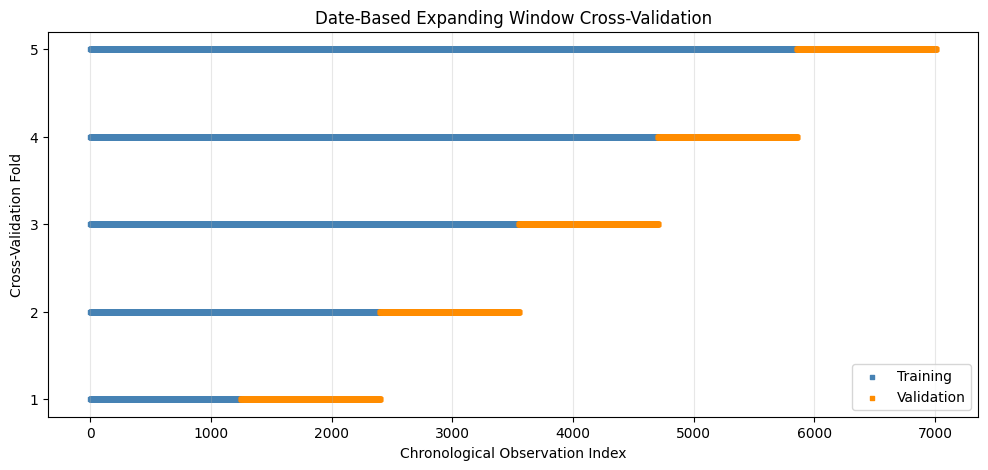

In [49]:
# Step 1: Verify chronological order and complete dates
for fold, (train_idx, val_idx) in enumerate(
    D1_cv_splits, start=1
):
    D1_fold_train_dates = D1_dates.iloc[train_idx]
    D1_fold_val_dates = D1_dates.iloc[val_idx]

    assert D1_fold_train_dates.max() < D1_fold_val_dates.min()

    assert set(D1_fold_train_dates).isdisjoint(
        set(D1_fold_val_dates)
    )

    print(
        f'Fold {fold}: '
        f'{len(train_idx)} training rows, '
        f'{len(val_idx)} validation rows'
    )

print('\nAll date-based CV checks passed.')

# Step 2: Visualize folds
plt.figure(figsize=(12, 5))

for fold, (train_idx, val_idx) in enumerate(
    D1_cv_splits, start=1
):
    plt.scatter(
        train_idx,
        np.full(len(train_idx), fold),
        color='steelblue',
        marker='s',
        s=6,
        label='Training' if fold == 1 else None
    )

    plt.scatter(
        val_idx,
        np.full(len(val_idx), fold),
        color='darkorange',
        marker='s',
        s=6,
        label='Validation' if fold == 1 else None
    )

plt.xlabel('Chronological Observation Index')
plt.ylabel('Cross-Validation Fold')
plt.title('Date-Based Expanding Window Cross-Validation')
plt.yticks(range(1, 6))
plt.legend()
plt.grid(axis='x', alpha=0.3)
plt.show()

**Date-Based Cross-Validation**

To ensure consistency with the original chronological train-test split, cross-validation folds were constructed using unique calendar dates rather than individual hourly observations.

TimeSeriesSplit was applied to the ordered unique dates, and the resulting date groups were mapped back to hourly observations.

This approach ensures that:

- All hourly observations from the same date remain within the same fold partition.
- Training observations always precede validation observations.
- Training windows expand progressively across folds.
- Each validation fold represents a continuous period of complete days.
- The held-out testing dataset remains excluded from cross-validation.

Five date-based folds were constructed to evaluate model generalization across successive chronological periods.

### D1.2. Cross-Validation Performance Evaluation

The baseline Random Forest model is evaluated across five chronological validation folds.

For each fold, the model is trained using the corresponding training observations and evaluated on the subsequent validation period.

Three metrics are calculated:

- **MAE:** Average absolute prediction error.
- **RMSE:** Root mean squared prediction error.
- **R²:** Predictive performance relative to the mean of the validation target.

Training and validation performance are both recorded to examine potential overfitting.

The same preprocessing pipeline is refitted independently within each fold to prevent preprocessing leakage.

Cross-validation results are summarized using the mean and standard deviation across the five validation folds.

In [50]:
# Step 1: Initialize results
D1_cv_results = []

# Step 2: Perform date-based cross-validation
for fold, (train_idx, val_idx) in enumerate(
    D1_cv_splits, start=1
):

    # Select training and validation data
    D1_X_train = X_train.iloc[train_idx]
    D1_X_val = X_train.iloc[val_idx]

    D1_y_train = y_train.iloc[train_idx]
    D1_y_val = y_train.iloc[val_idx]

    # Create a fresh model
    D1_model = clone(C2_model)

    # Train model
    D1_model.fit(D1_X_train, D1_y_train)

    # Generate predictions
    D1_y_train_pred = D1_model.predict(D1_X_train)
    D1_y_val_pred = D1_model.predict(D1_X_val)

    # Evaluate performance
    D1_train_metrics = C1_evaluate_regression(
        D1_y_train, D1_y_train_pred
    )

    D1_val_metrics = C1_evaluate_regression(
        D1_y_val, D1_y_val_pred
    )

    # Store results
    D1_cv_results.append({
        'Fold': fold,
        'Train MAE': D1_train_metrics['MAE'],
        'Train RMSE': D1_train_metrics['RMSE'],
        'Train R2': D1_train_metrics['R2'],
        'Validation MAE': D1_val_metrics['MAE'],
        'Validation RMSE': D1_val_metrics['RMSE'],
        'Validation R2': D1_val_metrics['R2']
    })

    print(
        f'Fold {fold}: '
        f'Train R² = {D1_train_metrics["R2"]:.4f}, '
        f'Validation R² = {D1_val_metrics["R2"]:.4f}'
    )

# Step 3: Display results
D1_results_df = pd.DataFrame(D1_cv_results)

display(D1_results_df.round(4))

Fold 1: Train R² = 0.9765, Validation R² = 0.5966
Fold 2: Train R² = 0.9823, Validation R² = 0.3559
Fold 3: Train R² = 0.9828, Validation R² = 0.5697
Fold 4: Train R² = 0.9868, Validation R² = 0.7157
Fold 5: Train R² = 0.9892, Validation R² = 0.7682


,Fold,Train MAE,Train RMSE,Train R2,Validation MAE,Validation RMSE,Validation R2
0,1,14.966,22.752,0.977,81.666,129.882,0.597
1,2,14.541,23.616,0.982,273.407,412.349,0.356
2,3,25.577,49.312,0.983,378.623,498.056,0.570
3,4,36.495,66.538,0.987,271.217,378.489,0.716
4,5,36.877,66.740,0.989,188.879,311.076,0.768


In [51]:
# Step 1: Calculate mean validation performance
D1_mean_mae = D1_results_df['Validation MAE'].mean()
D1_mean_rmse = D1_results_df['Validation RMSE'].mean()
D1_mean_r2 = D1_results_df['Validation R2'].mean()

# Step 2: Calculate standard deviations
D1_std_mae = D1_results_df['Validation MAE'].std()
D1_std_rmse = D1_results_df['Validation RMSE'].std()
D1_std_r2 = D1_results_df['Validation R2'].std()

# Step 3: Display results
print('Random Forest Time-Series Cross-Validation Results:')

print(f'Mean Validation MAE:  {D1_mean_mae:.4f} ± {D1_std_mae:.4f}')
print(f'Mean Validation RMSE: {D1_mean_rmse:.4f} ± {D1_std_rmse:.4f}')
print(f'Mean Validation R²:   {D1_mean_r2:.4f} ± {D1_std_r2:.4f}')

Random Forest Time-Series Cross-Validation Results:
Mean Validation MAE:  238.7583 ± 110.6597
Mean Validation RMSE: 345.9705 ± 138.2978
Mean Validation R²:   0.6012 ± 0.1598


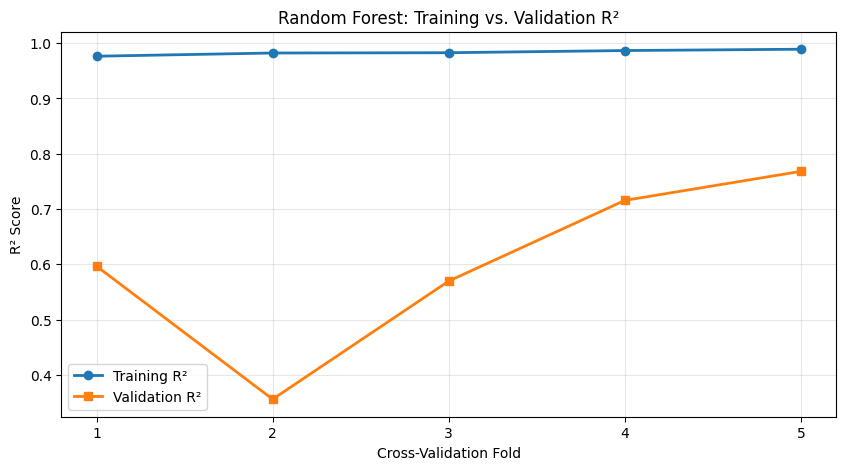

In [52]:
# Step 1: Plot training and validation R²
plt.figure(figsize=(10, 5))

plt.plot(
    D1_results_df['Fold'],
    D1_results_df['Train R2'],
    marker='o',
    linewidth=2,
    label='Training R²'
)

plt.plot(
    D1_results_df['Fold'],
    D1_results_df['Validation R2'],
    marker='s',
    linewidth=2,
    label='Validation R²'
)

# Step 2: Customize plot
plt.xlabel('Cross-Validation Fold')
plt.ylabel('R² Score')
plt.title('Random Forest: Training vs. Validation R²')
plt.xticks(D1_results_df['Fold'])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

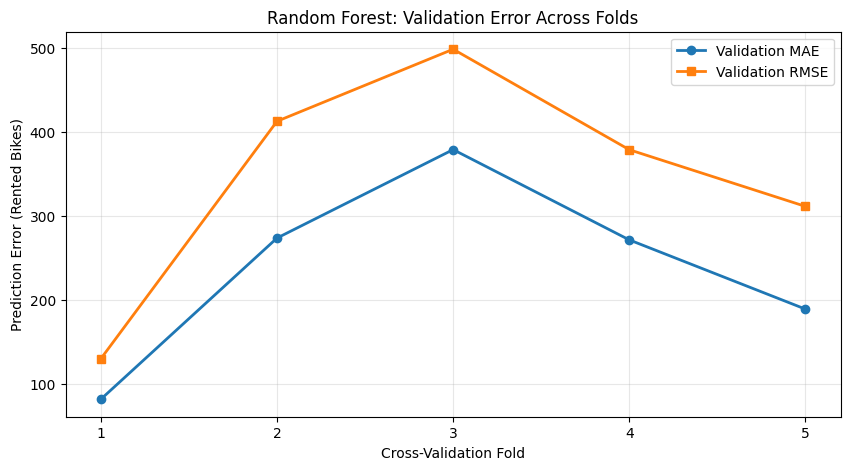

In [53]:
# Plot validation MAE and RMSE across folds
plt.figure(figsize=(10, 5))

plt.plot(
    D1_results_df['Fold'],
    D1_results_df['Validation MAE'],
    marker='o',
    linewidth=2,
    label='Validation MAE'
)

plt.plot(
    D1_results_df['Fold'],
    D1_results_df['Validation RMSE'],
    marker='s',
    linewidth=2,
    label='Validation RMSE'
)

plt.xlabel('Cross-Validation Fold')
plt.ylabel('Prediction Error (Rented Bikes)')
plt.title('Random Forest: Validation Error Across Folds')
plt.xticks(D1_results_df['Fold'])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### D1.3. Time-Series Cross-Validation Summary

Five-fold Date-Based Expanding Window Cross-Validation was implemented to evaluate the baseline Random Forest Regressor across successive chronological periods.

Unlike conventional random cross-validation, this approach preserves temporal ordering and ensures that all hourly observations from the same calendar date remain within the same training or validation partition.

The cross-validation procedure was performed exclusively on the training dataset, while the held-out testing dataset remained excluded from model selection.

**1. Cross-Validation Strategy**

The original training dataset contained 292 complete days of hourly rental observations.

Five expanding-window folds were constructed using unique calendar dates. Each subsequent fold included additional historical observations in the training set, while validation was performed on the following 48 complete days.

| Fold | Training Days | Validation Days | Training Samples | Validation Samples |
|---|---:|---:|---:|---:|
| 1 | 52 | 48 | 1,248 | 1,152 |
| 2 | 100 | 48 | 2,400 | 1,152 |
| 3 | 148 | 48 | 3,552 | 1,152 |
| 4 | 196 | 48 | 4,704 | 1,152 |
| 5 | 244 | 48 | 5,856 | 1,152 |

Preprocessing and model fitting were performed independently within each fold to avoid preprocessing leakage.

**2. Cross-Validation Performance**

The baseline Random Forest model was evaluated using MAE, RMSE, and R² across all five validation folds.

| Fold | Training R² | Validation R² | Validation MAE | Validation RMSE |
|---|---:|---:|---:|---:|
| 1 | 0.9765 | 0.5966 | 81.67 | 129.88 |
| 2 | 0.9823 | 0.3559 | 273.41 | 412.35 |
| 3 | 0.9828 | 0.5697 | 378.62 | 498.06 |
| 4 | 0.9868 | 0.7157 | 271.22 | 378.49 |
| 5 | 0.9892 | 0.7682 | 188.88 | 311.08 |

**Cross-Validation Summary Statistics**

| Metric | Mean | Standard Deviation |
|---|---:|---:|
| Validation MAE | 238.76 | 110.66 |
| Validation RMSE | 345.97 | 138.30 |
| Validation R² | 0.6012 | 0.1598 |

The model achieved a mean validation R² of 0.6012, with substantial variability across chronological validation periods.

This indicates that predictive performance depends on the training history and the characteristics of each validation period.

**3. Generalization and Overfitting Analysis**

Training R² remained consistently high across all folds, ranging from 0.9765 to 0.9892.

In contrast, validation R² ranged from 0.3559 to 0.7682, indicating a substantial gap between training and validation performance.

These results suggest that the baseline Random Forest may be overfitting the training observations.

However, temporal distribution shifts, seasonal differences, and changes in rental demand may also contribute to the observed performance gaps.

**4. Performance Across Chronological Folds**

Fold 2 achieved the lowest validation R² (0.3559), while Fold 3 produced the highest absolute prediction errors (MAE = 378.62 and RMSE = 498.06).

Validation performance improved in later folds, reaching R² values of 0.7157 and 0.7682 in Folds 4 and 5, respectively.

This pattern is consistent with the possibility that additional historical observations help the model learn a broader range of demand patterns.

Nevertheless, changes in validation-period characteristics may also contribute to these differences, so the improvement cannot be attributed solely to increasing training-set size.

**5. Comparison with Hour-Based Cross-Validation**

The original hour-based TimeSeriesSplit produced a mean validation R² of 0.6341, compared with 0.6012 using date-based splitting.

The date-based approach also produced slightly higher mean MAE and RMSE.

These differences demonstrate that model evaluation is sensitive to the positioning of chronological validation boundaries.

Date-based splitting was retained because it preserves complete calendar days and is consistent with the project's date-based train-test strategy.

**6. Implications for Model Optimization**

The cross-validation results highlight the importance of evaluating generalization across multiple chronological periods rather than relying exclusively on training performance or a single holdout split.

The consistently high training R² and variable validation performance motivate further investigation of model complexity.

The next stage will use RandomizedSearchCV with the same date-based chronological folds to optimize Random Forest hyperparameters.

The optimization will focus on parameters such as:

- `max_depth`
- `min_samples_split`
- `min_samples_leaf`
- `max_features`
- `n_estimators`

The primary optimization objective will be to reduce mean cross-validation RMSE while maintaining generalization across different validation periods.

**Key Takeaways:**

- Five date-based expanding-window folds were successfully constructed.
- All hourly observations from the same calendar day remained within the same fold partition.
- The baseline Random Forest achieved a mean validation MAE of 238.76, RMSE of 345.97, and R² of 0.6012.
- Validation R² varied substantially, ranging from 0.3559 to 0.7682.
- Training R² remained above 0.97 across all five folds, suggesting potential overfitting.
- Later validation folds generally achieved higher R² scores than earlier folds.
- Date-based cross-validation provides a consistent framework for chronological model evaluation.
- Hyperparameter optimization is required to investigate whether limiting model complexity can improve validation performance.

The next section applies RandomizedSearchCV with date-based chronological folds to optimize Random Forest performance while preserving the held-out testing dataset for final evaluation.

## D2. Random Forest Hyperparameter Tuning

The baseline Random Forest model demonstrated substantially better predictive performance than Linear Regression, but showed a large gap between training and validation performance.

Date-based expanding-window cross-validation produced the following baseline results:

| Metric | Mean Validation Score |
|---|---:|
| MAE | 238.76 |
| RMSE | 345.97 |
| R² | 0.6012 |

To investigate whether model complexity can be reduced while improving generalization, RandomizedSearchCV is used to optimize the Random Forest hyperparameters.

The search uses five date-based chronological cross-validation folds established in Part D1.

**Optimization Objectives:**

1. Minimize mean cross-validation RMSE.
2. Reduce potential overfitting by controlling tree complexity.
3. Compare the tuned model with the original Random Forest baseline using identical cross-validation folds.
4. Examine the stability of validation performance across chronological periods.

The held-out testing dataset is excluded from hyperparameter selection.

### D2.1. Hyperparameter Search Strategy

RandomizedSearchCV evaluates a fixed number of randomly sampled hyperparameter combinations rather than exhaustively evaluating every possible combination.

The following Random Forest hyperparameters are investigated:

| Hyperparameter | Purpose |
|---|---|
| `n_estimators` | Number of decision trees in the forest |
| `max_depth` | Maximum depth of each decision tree |
| `min_samples_split` | Minimum number of samples required to split an internal node |
| `min_samples_leaf` | Minimum number of samples required at a leaf node |
| `max_features` | Proportion of features considered at each split |

Parameters such as max_depth, min_samples_split, and min_samples_leaf control model complexity and may help reduce overfitting.

The optimization metric is Root Mean Squared Error (RMSE), which places greater emphasis on large prediction errors.

Scikit-learn uses `neg_root_mean_squared_error` because its hyperparameter search interface selects the configuration with the highest score. The negative sign is reversed when reporting RMSE.

Thirty parameter combinations are evaluated using five chronological validation folds.

The configuration with the lowest mean validation RMSE is selected and refitted on the complete training dataset.

In [54]:
# Step 1: Define Random Forest hyperparameter search space
D2_param_grid = {
    'regressor__n_estimators': [100, 200, 300],
    'regressor__max_depth': [5, 10, 15, 20, None],
    'regressor__min_samples_split': [2, 5, 10, 20],
    'regressor__min_samples_leaf': [1, 2, 4, 8],
    'regressor__max_features': [0.5, 0.75, 1.0]
}

# Step 2: Count all possible combinations
D2_total_combinations = np.prod([
    len(values) for values in D2_param_grid.values()
])

print(f'Total Possible Combinations: {D2_total_combinations}')
print('Randomized Search Iterations: 30')
print('Cross-Validation Folds:', len(D1_cv_splits))
print('Total CV Fits:', 30 * len(D1_cv_splits))

Total Possible Combinations: 720
Randomized Search Iterations: 30
Cross-Validation Folds: 5
Total CV Fits: 150


In [55]:
# Step 1: Create a model for hyperparameter tuning
D2_base_model = clone(C2_model)
D2_base_model.set_params(regressor__n_jobs=1)

# Step 2: Configure RandomizedSearchCV
D2_search = RandomizedSearchCV(
    estimator=D2_base_model,
    param_distributions=D2_param_grid,
    n_iter=30,
    scoring='neg_root_mean_squared_error',
    cv=D1_cv_splits,
    random_state=42,
    n_jobs=2,
    verbose=1,
    refit=True
)

# Step 3: Run hyperparameter search
D2_search.fit(X_train, y_train)

# Step 4: Extract best model
D2_best_model = D2_search.best_estimator_

print('\nBest Hyperparameters:')
for param, value in D2_search.best_params_.items():
    print(f'{param}: {value}')

print(f'\nBest Mean CV RMSE: {-D2_search.best_score_:.4f}')

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best Hyperparameters:
regressor__n_estimators: 200
regressor__min_samples_split: 5
regressor__min_samples_leaf: 1
regressor__max_features: 0.75
regressor__max_depth: 15

Best Mean CV RMSE: 343.2160


### D2.2. Hyperparameter Search Results

RandomizedSearchCV was performed using 30 randomly selected hyperparameter configurations and five date-based chronological validation folds.

The search was optimized using mean validation RMSE.

The results were ranked according to their average cross-validation performance, with lower RMSE indicating better predictive accuracy.

The best-performing configuration was selected and refitted on the complete training dataset.

The optimized model is subsequently compared with the baseline Random Forest to evaluate changes in cross-validation performance and generalization.

In [56]:
# Step 1: Collect search results
D2_search_results = pd.DataFrame(D2_search.cv_results_)

# Step 2: Convert negative RMSE to positive RMSE
D2_search_results['Mean CV RMSE'] = (
    -D2_search_results['mean_test_score']
)

D2_search_results['Std CV RMSE'] = (
    D2_search_results['std_test_score']
)

# Step 3: Select relevant columns
D2_top_results = D2_search_results[
    [
        'rank_test_score',
        'Mean CV RMSE',
        'Std CV RMSE',
        'param_regressor__n_estimators',
        'param_regressor__max_depth',
        'param_regressor__min_samples_split',
        'param_regressor__min_samples_leaf',
        'param_regressor__max_features'
    ]
].sort_values('rank_test_score').head(10)

display(D2_top_results.round(4))

,rank_test_score,Mean CV RMSE,Std CV RMSE,param_regressor__n_estimators,param_regressor__max_depth,param_regressor__min_samples_split,param_regressor__min_samples_leaf,param_regressor__max_features
0,1,343.216,129.818,200,15,5,1,0.750
17,2,349.288,135.849,100,None,5,1,0.750
23,3,349.726,125.641,300,None,2,2,1.000
9,4,350.858,126.332,100,15,10,1,1.000
26,5,351.431,126.424,300,10,2,2,1.000
1,6,351.826,139.170,300,15,2,1,0.500
8,7,352.579,140.534,200,15,5,1,0.500
20,8,353.416,140.638,300,20,2,2,0.500
18,9,353.610,126.845,200,10,10,2,1.000
3,10,354.128,135.745,100,10,10,1,0.750


In [57]:
# Step 1: Baseline CV performance
D2_baseline_cv_rmse = D1_mean_rmse

# Step 2: Tuned CV performance
D2_tuned_cv_rmse = -D2_search.best_score_

# Step 3: Calculate RMSE improvement
D2_cv_improvement = (
    (D2_baseline_cv_rmse - D2_tuned_cv_rmse)
    / D2_baseline_cv_rmse * 100
)

# Step 4: Compare results
D2_cv_comparison = pd.DataFrame({
    'Model': [
        'Baseline Random Forest',
        'Tuned Random Forest'
    ],
    'Mean CV RMSE': [
        D2_baseline_cv_rmse,
        D2_tuned_cv_rmse
    ]
})

display(D2_cv_comparison.round(4))

print(f'CV RMSE Reduction: {D2_cv_improvement:+.2f}%')

,Model,Mean CV RMSE
0,Baseline Random Forest,345.971
1,Tuned Random Forest,343.216


CV RMSE Reduction: +0.80%


,Fold,Baseline RMSE,Tuned RMSE,RMSE Reduction (%)
0,1,129.882,130.018,-0.104
1,2,412.349,403.943,2.039
2,3,498.056,524.443,-5.298
3,4,378.489,359.382,5.048
4,5,311.076,298.294,4.109


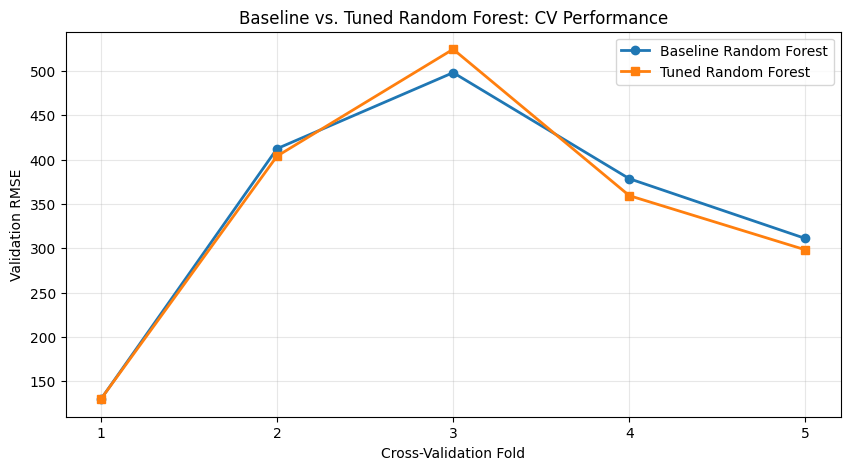

In [58]:
# Step 1: Extract best model's CV results
D2_best_index = D2_search.best_index_

D2_fold_comparison = pd.DataFrame({
    'Fold': D1_results_df['Fold'],
    'Baseline RMSE': D1_results_df['Validation RMSE'],
    'Tuned RMSE': [
        -D2_search.cv_results_[
            f'split{i}_test_score'
        ][D2_best_index]
        for i in range(5)
    ]
})

# Step 2: Calculate improvement for each fold
D2_fold_comparison['RMSE Reduction (%)'] = (
    (D2_fold_comparison['Baseline RMSE']
     - D2_fold_comparison['Tuned RMSE'])
    / D2_fold_comparison['Baseline RMSE'] * 100
)

display(D2_fold_comparison.round(4))

# Step 3: Visualize fold-by-fold results
plt.figure(figsize=(10, 5))

plt.plot(
    D2_fold_comparison['Fold'],
    D2_fold_comparison['Baseline RMSE'],
    marker='o',
    linewidth=2,
    label='Baseline Random Forest'
)

plt.plot(
    D2_fold_comparison['Fold'],
    D2_fold_comparison['Tuned RMSE'],
    marker='s',
    linewidth=2,
    label='Tuned Random Forest'
)

plt.xlabel('Cross-Validation Fold')
plt.ylabel('Validation RMSE')
plt.title('Baseline vs. Tuned Random Forest: CV Performance')
plt.xticks(D2_fold_comparison['Fold'])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### D2.3. Generalization Analysis

Hyperparameter tuning aims to improve performance on unseen observations rather than maximize training accuracy.

To examine the effect of tuning on model complexity, the baseline and optimized Random Forest models are compared using their training performance.

A reduction in training R² is not necessarily undesirable. If lower training accuracy is accompanied by improved cross-validation performance, it may indicate that the optimized model is less sensitive to training-specific patterns.

However, cross-validation performance remains the primary criterion for model selection.

In [59]:
# Step 1: Generate tuned model training predictions
D2_y_train_pred = D2_best_model.predict(X_train)

# Step 2: Evaluate tuned training performance
D2_train_metrics = C1_evaluate_regression(
    y_train, D2_y_train_pred
)

# Step 3: Compare with baseline Random Forest
D2_train_comparison = pd.DataFrame({
    'Baseline Random Forest': C2_train_metrics,
    'Tuned Random Forest': D2_train_metrics
}).T

display(D2_train_comparison.round(4))

print(
    'Baseline Training R²:',
    f'{C2_train_metrics["R2"]:.4f}'
)

print(
    'Tuned Training R²:',
    f'{D2_train_metrics["R2"]:.4f}'
)

,MAE,RMSE,R2
Baseline Random Forest,37.425,67.203,0.989
Tuned Random Forest,52.569,89.266,0.981


Baseline Training R²: 0.9894
Tuned Training R²: 0.9813


### D2.4. Hyperparameter Tuning Summary

RandomizedSearchCV was implemented to optimize the Random Forest Regressor using five date-based expanding-window cross-validation folds.

A total of 30 randomly selected hyperparameter configurations were evaluated, resulting in 150 cross-validation fits. The primary optimization objective was to minimize mean validation RMSE.

**1. Optimal Hyperparameters**

The following configuration achieved the lowest mean cross-validation RMSE among the evaluated candidates:

| Hyperparameter | Optimal Value |
|---|---|
| `n_estimators` | 200 |
| `max_depth` | 15 |
| `min_samples_split` | 5 |
| `min_samples_leaf` | 1 |
| `max_features` | 0.75 |

Compared with the baseline Random Forest, the selected configuration uses more trees while restricting tree depth and increasing the minimum number of samples required for a split.

These changes aim to reduce model complexity and improve generalization.

**2. Cross-Validation Performance**

| Model | Mean CV RMSE |
|---|---:|
| Baseline Random Forest | 345.97 |
| Tuned Random Forest | 343.22 |

Hyperparameter tuning reduced mean cross-validation RMSE by 0.80%.

Although the tuned model achieved the lowest average RMSE among the sampled configurations, the improvement over the baseline was relatively small.

**3. Fold-by-Fold Performance**

| Fold | Baseline RMSE | Tuned RMSE | RMSE Reduction |
|---|---:|---:|---:|
| 1 | 129.88 | 130.02 | -0.10% |
| 2 | 412.35 | 403.94 | 2.04% |
| 3 | 498.06 | 524.44 | -5.30% |
| 4 | 378.49 | 359.38 | 5.05% |
| 5 | 311.08 | 298.29 | 4.11% |

The tuned model improved validation RMSE in three of the five folds.

The largest improvement occurred in Fold 4, where RMSE decreased by 5.05%.

However, Fold 3 experienced a 5.30% increase in RMSE, demonstrating that the benefits of hyperparameter optimization were not consistent across all chronological periods.

The relatively small overall improvement and variation across folds indicate that the optimized model does not consistently outperform the baseline across different validation periods.

**4. Training Performance and Model Complexity**

| Metric | Baseline RF | Tuned RF |
|---|---:|---:|
| Training MAE | 37.43 | 52.57 |
| Training RMSE | 67.20 | 89.27 |
| Training R² | 0.9894 | 0.9813 |

The tuned model achieved a lower training R² and higher training prediction errors compared with the baseline.

These results indicate reduced fitting of the training observations, consistent with the increased regularization introduced through the selected hyperparameters.

However, the modest improvement in cross-validation RMSE suggests that controlling tree complexity alone may not be sufficient to address the model's generalization limitations.

**5. Interpretation and Limitations**

The tuning results suggest that the original Random Forest may have been unnecessarily complex, but reducing complexity produced only a limited improvement in chronological validation performance.

Several factors may contribute to the remaining prediction errors:

- Seasonal and temporal differences between training and validation periods.
- Limited representation of some demand conditions in earlier training folds.
- Potential interactions and nonlinear relationships not fully captured by the selected model.
- High-demand and non-operational observations that remain challenging to predict accurately.

Furthermore, the best configuration was selected using the same cross-validation folds used to report its performance. Therefore, the selected cross-validation score may be somewhat optimistic.

Independent evaluation on the held-out testing dataset is necessary to assess whether the observed improvement generalizes to unseen chronological observations.

**6. Next Steps**

The optimized Random Forest will be evaluated on the original held-out testing dataset and compared against the Linear Regression and baseline Random Forest models.

Further analysis will examine prediction errors under high-demand and zero-demand conditions.

Business-rule integration and feature importance analysis may also be explored to improve prediction consistency and interpretability.

**Key Takeaways:**

- RandomizedSearchCV evaluated 30 hyperparameter configurations across five chronological folds.
- The selected model uses 200 trees, a maximum depth of 15, and a minimum split size of 5.
- Mean CV RMSE decreased from 345.97 to 343.22, representing a 0.80% improvement.
- Validation RMSE improved in three of five folds but worsened in the remaining two.
- Training R² decreased from 0.9894 to 0.9813, indicating reduced training-data fit.
- The limited cross-validation improvement suggests that hyperparameter tuning alone may not substantially improve generalization.
- Final model selection requires independent evaluation on the held-out testing dataset.

The next section evaluates the tuned Random Forest on the held-out testing dataset and compares its performance with the original baseline models.

# Part E: Final Model Evaluation

Following baseline model development, chronological cross-validation, and hyperparameter optimization, the selected Random Forest model is evaluated on the original held-out testing dataset.

The dataset was initially divided chronologically, with the earliest 80% of dates used for model development and the latest 20% reserved for final evaluation.

Three models are compared:

1. **Linear Regression:** An interpretable linear baseline.
2. **Baseline Random Forest:** A nonlinear ensemble model using default tree complexity settings.
3. **Tuned Random Forest:** A Random Forest optimized using RandomizedSearchCV and five date-based expanding-window validation folds.

The final evaluation focuses on:

- Predictive accuracy using MAE, RMSE, and R².
- Generalization from training to unseen chronological observations.
- Performance under high-demand and zero-demand conditions.
- Residual patterns and systematic prediction errors.

The testing dataset was excluded from hyperparameter optimization. No additional hyperparameters will be selected based on the final testing results.

In [60]:
# Step 1: Generate predictions from the tuned model
E_y_test_pred = D2_best_model.predict(X_test)

# Step 2: Evaluate tuned Random Forest
E_tuned_metrics = C1_evaluate_regression(
    y_test, E_y_test_pred
)

# Step 3: Display results
print('Tuned Random Forest - Final Test Performance')
print(f'MAE:  {E_tuned_metrics["MAE"]:.4f}')
print(f'RMSE: {E_tuned_metrics["RMSE"]:.4f}')
print(f'R²:   {E_tuned_metrics["R2"]:.4f}')

Tuned Random Forest - Final Test Performance
MAE:  269.1287
RMSE: 357.5682
R²:   0.6601


In [61]:
# Compare All Three Models
# Step 1: Collect final testing metrics
E_model_comparison = pd.DataFrame({
    'Linear Regression': C1_test_metrics,
    'Baseline Random Forest': C2_test_metrics,
    'Tuned Random Forest': E_tuned_metrics
}).T

# Step 2: Calculate improvement over baseline Random Forest
E_rmse_improvement = (
    (C2_test_metrics['RMSE'] - E_tuned_metrics['RMSE'])
    / C2_test_metrics['RMSE'] * 100
)

E_mae_improvement = (
    (C2_test_metrics['MAE'] - E_tuned_metrics['MAE'])
    / C2_test_metrics['MAE'] * 100
)

E_r2_difference = (
    E_tuned_metrics['R2'] - C2_test_metrics['R2']
)

# Step 3: Display model comparison
display(E_model_comparison.round(4))

print('Tuned vs. Baseline Random Forest:')
print(f'MAE Reduction:  {E_mae_improvement:+.2f}%')
print(f'RMSE Reduction: {E_rmse_improvement:+.2f}%')
print(f'R² Difference:  {E_r2_difference:+.4f}')

,MAE,RMSE,R2
Linear Regression,306.478,426.215,0.517
Baseline Random Forest,264.164,361.818,0.652
Tuned Random Forest,269.129,357.568,0.660


Tuned vs. Baseline Random Forest:
MAE Reduction:  -1.88%
RMSE Reduction: +1.17%
R² Difference:  +0.0081


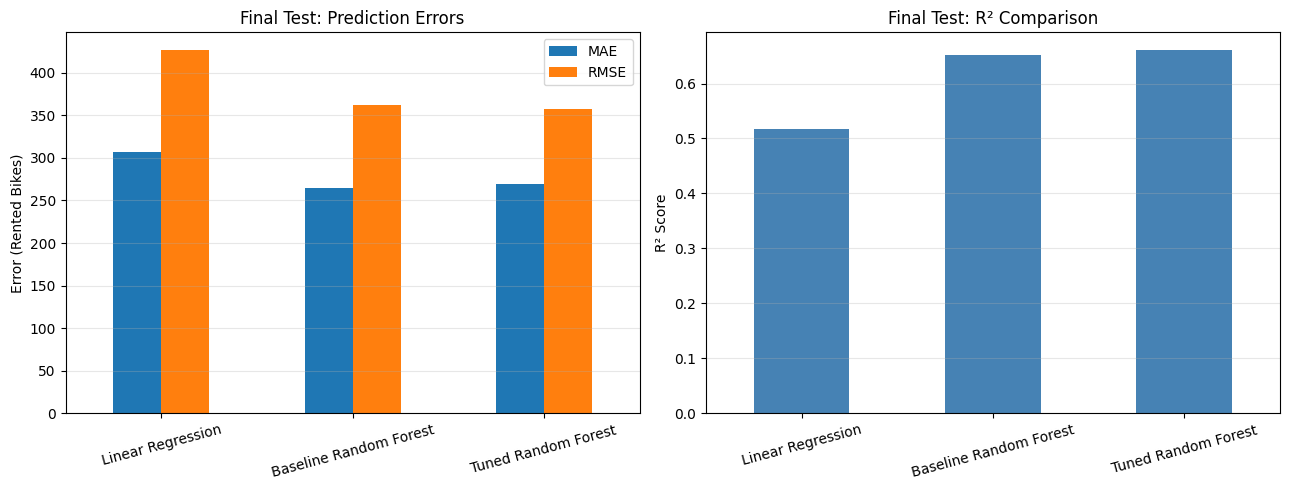

In [62]:
# Step 1: Create comparison plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

E_model_comparison[['MAE', 'RMSE']].plot(
    kind='bar',
    ax=axes[0],
    rot=15
)

axes[0].set_title('Final Test: Prediction Errors')
axes[0].set_ylabel('Error (Rented Bikes)')
axes[0].set_xlabel('')
axes[0].grid(axis='y', alpha=0.3)

E_model_comparison['R2'].plot(
    kind='bar',
    ax=axes[1],
    color='steelblue',
    rot=15
)

axes[1].set_title('Final Test: R² Comparison')
axes[1].set_ylabel('R² Score')
axes[1].set_xlabel('')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### E1. Generalization Analysis

The tuned Random Forest was selected based on its average cross-validation RMSE across five chronological validation folds.

Its final test performance is compared with the baseline Random Forest to assess whether the cross-validation improvement extends to the unseen testing period.

Training and testing metrics are also compared to investigate the generalization gap.

A smaller training-testing gap may indicate reduced overfitting, but it does not necessarily imply better predictive accuracy. Final testing performance must therefore be interpreted alongside training and cross-validation results.

In [63]:
# Step 1: Build generalization comparison
E_generalization = pd.DataFrame({
    'Model': [
        'Baseline Random Forest',
        'Tuned Random Forest'
    ],
    'Training R2': [
        C2_train_metrics['R2'],
        D2_train_metrics['R2']
    ],
    'Testing R2': [
        C2_test_metrics['R2'],
        E_tuned_metrics['R2']
    ],
    'Training RMSE': [
        C2_train_metrics['RMSE'],
        D2_train_metrics['RMSE']
    ],
    'Testing RMSE': [
        C2_test_metrics['RMSE'],
        E_tuned_metrics['RMSE']
    ]
})

# Step 2: Calculate generalization gap
E_generalization['R2 Gap'] = (
    E_generalization['Training R2']
    - E_generalization['Testing R2']
)

display(E_generalization.round(4))

,Model,Training R2,Testing R2,Training RMSE,Testing RMSE,R2 Gap
0,Baseline Random Forest,0.989,0.652,67.203,361.818,0.337
1,Tuned Random Forest,0.981,0.660,89.266,357.568,0.321


### E2. Demand-Specific Prediction Diagnostics

Overall evaluation metrics may conceal differences in prediction performance under specific operating conditions.

Previous analyses identified two challenging scenarios:

1. **High-Demand Observations:** Hourly rentals exceeding the IQR upper threshold of 2,376.62.
2. **Zero-Demand Observations:** Observations with no recorded rentals, all of which occurred during non-operational periods in the testing dataset.

The three models are compared using MAE for each category.

This analysis evaluates whether improvements in overall predictive performance also extend to operationally important demand conditions.

In [64]:
# Step 1: Define demand conditions
E_high_mask = (y_test > B1_upper_bound).to_numpy()
E_zero_mask = (y_test == 0).to_numpy()

# Step 2: Collect model predictions
E_predictions = {
    'Linear Regression': C1_y_test_pred,
    'Baseline Random Forest': C2_y_test_pred,
    'Tuned Random Forest': E_y_test_pred
}

# Step 3: Calculate MAE for each demand category
E_diagnostic_results = []

for name, pred in E_predictions.items():
    E_diagnostic_results.append({
        'Model': name,
        'Overall MAE': mean_absolute_error(y_test, pred),
        'High-Demand MAE': mean_absolute_error(
            y_test.to_numpy()[E_high_mask],
            pred[E_high_mask]
        ),
        'Zero-Demand MAE': mean_absolute_error(
            y_test.to_numpy()[E_zero_mask],
            pred[E_zero_mask]
        ),
        'Negative Predictions': int(np.sum(pred < 0))
    })

# Step 4: Display results
E_diagnostic_df = pd.DataFrame(
    E_diagnostic_results
).set_index('Model')

display(E_diagnostic_df.round(2))

print(f'High-Demand Observations: {E_high_mask.sum()}')
print(f'Zero-Demand Observations: {E_zero_mask.sum()}')

,Overall MAE,High-Demand MAE,Zero-Demand MAE,Negative Predictions
Model,,,,
Linear Regression,306.480,1193.330,341.420,135
Baseline Random Forest,264.160,603.850,174.740,0
Tuned Random Forest,269.130,672.340,236.760,0


High-Demand Observations: 19
Zero-Demand Observations: 223


### E3. Residual Analysis

Residual analysis is performed to investigate prediction errors beyond aggregate performance metrics.

A residual is defined as:

$$
e_i = y_i - \hat{y}_i
$$

where:

- $y_i$ is the actual rental count.
- $\hat{y}_i$ is the predicted rental count.

Residuals are interpreted as follows:

- **Positive residual:** The model underestimated rental demand.
- **Negative residual:** The model overestimated rental demand.
- **Residual near zero:** The prediction is close to the actual demand.

An ideal residual distribution is centered near zero without strong systematic patterns.

Residual plots help identify prediction bias, changes in error magnitude, and demand conditions where the model performs poorly.

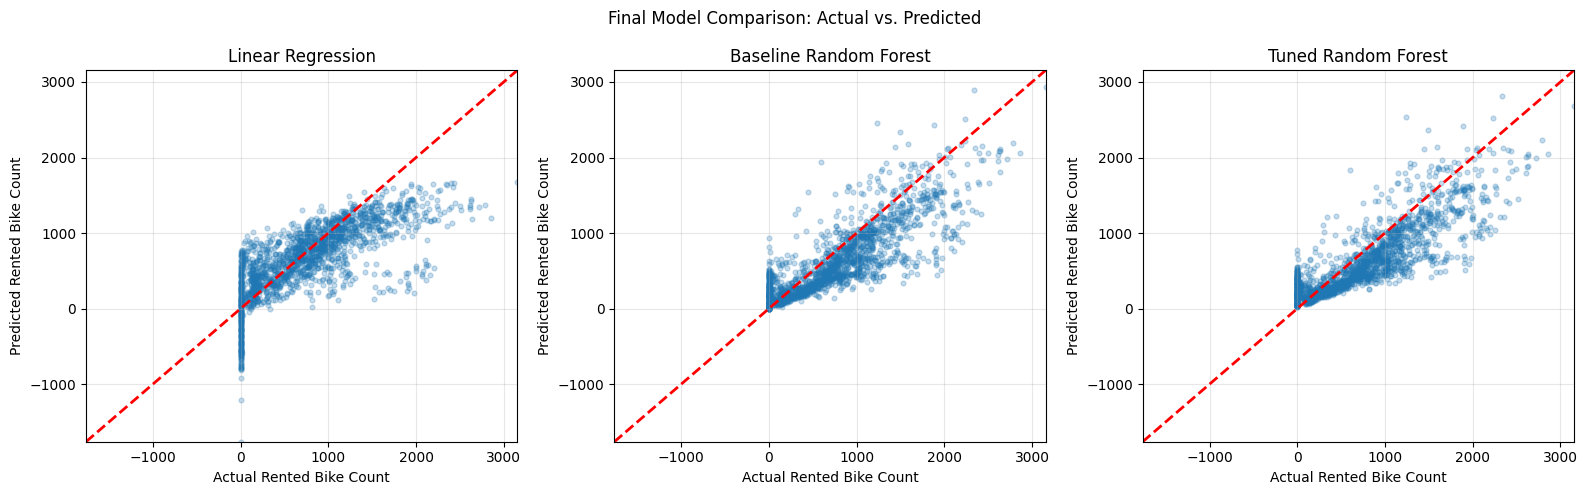

In [65]:
# Step 1: Set common plot limits
E_plot_min = min(
    y_test.min(),
    *(pred.min() for pred in E_predictions.values())
)

E_plot_max = max(
    y_test.max(),
    *(pred.max() for pred in E_predictions.values())
)

# Step 2: Plot all three models
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, pred) in zip(axes, E_predictions.items()):
    ax.scatter(
        y_test,
        pred,
        alpha=0.25,
        s=12
    )

    ax.plot(
        [E_plot_min, E_plot_max],
        [E_plot_min, E_plot_max],
        'r--',
        linewidth=2
    )

    ax.set_title(name)
    ax.set_xlabel('Actual Rented Bike Count')
    ax.set_ylabel('Predicted Rented Bike Count')
    ax.set_xlim(E_plot_min, E_plot_max)
    ax.set_ylim(E_plot_min, E_plot_max)
    ax.grid(True, alpha=0.3)

plt.suptitle('Final Model Comparison: Actual vs. Predicted')
plt.tight_layout()
plt.show()

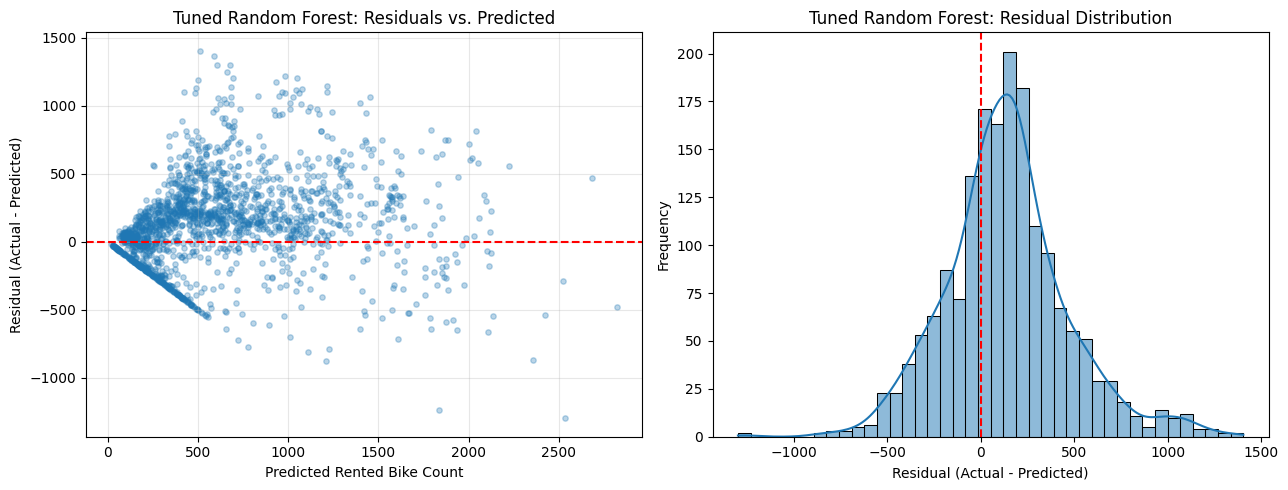

Mean Residual: 136.44
Median Residual: 128.44
Residual Std: 330.51


In [66]:
# Step 1: Calculate residuals
E_residuals = y_test.to_numpy() - E_y_test_pred

# Step 2: Create residual plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Residual vs. Predicted
axes[0].scatter(
    E_y_test_pred,
    E_residuals,
    alpha=0.3,
    s=15
)

axes[0].axhline(
    y=0,
    color='red',
    linestyle='--'
)

axes[0].set_title('Tuned Random Forest: Residuals vs. Predicted')
axes[0].set_xlabel('Predicted Rented Bike Count')
axes[0].set_ylabel('Residual (Actual - Predicted)')
axes[0].grid(True, alpha=0.3)

# Residual distribution
sns.histplot(
    E_residuals,
    bins=40,
    kde=True,
    ax=axes[1]
)

axes[1].axvline(
    x=0,
    color='red',
    linestyle='--'
)

axes[1].set_title('Tuned Random Forest: Residual Distribution')
axes[1].set_xlabel('Residual (Actual - Predicted)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Step 3: Display residual statistics
print(f'Mean Residual: {E_residuals.mean():.2f}')
print(f'Median Residual: {np.median(E_residuals):.2f}')
print(f'Residual Std: {E_residuals.std():.2f}')

### E4. Final Model Evaluation Summary

Three regression models were evaluated on the original held-out chronological testing dataset containing 1,752 hourly observations:

1. Linear Regression
2. Baseline Random Forest
3. Tuned Random Forest

The tuned Random Forest was selected using RandomizedSearchCV with five date-based expanding-window cross-validation folds. The testing dataset was excluded from hyperparameter selection.

**1. Final Model Performance**

| Model | Test MAE | Test RMSE | Test R² |
|---|---:|---:|---:|
| Linear Regression | 306.48 | 426.22 | 0.5171 |
| Baseline Random Forest | 264.16 | 361.82 | 0.6520 |
| Tuned Random Forest | 269.13 | 357.57 | 0.6601 |

Both Random Forest models substantially outperformed the Linear Regression baseline, demonstrating the importance of nonlinear relationships and feature interactions in predicting bike rental demand.

Compared with the baseline Random Forest, the tuned model:

- Reduced test RMSE by 1.17%.
- Increased test R² by 0.0081.
- Increased test MAE by 1.88%.

These findings indicate that hyperparameter optimization provided a modest improvement in squared-error-based performance but did not consistently improve all evaluation metrics.

**2. Generalization Analysis**

| Metric | Baseline RF | Tuned RF |
|---|---:|---:|
| Training R² | 0.9894 | 0.9813 |
| Testing R² | 0.6520 | 0.6601 |
| R² Gap | 0.337 | 0.321 |
| Training RMSE | 67.20 | 89.27 |
| Testing RMSE | 361.82 | 357.57 |

The tuned Random Forest achieved slightly better testing R² and RMSE while exhibiting lower training performance.

The training-testing R² gap decreased from approximately 0.337 to 0.321.

This pattern is consistent with a modest reduction in overfitting, although the remaining generalization gap indicates that further limitations persist.

Temporal distribution shifts may also contribute to the difference between training and testing performance.

**3. Demand-Specific Prediction Performance**

Prediction errors were examined separately for high-demand and zero-demand observations.

| Model | Overall MAE | High-Demand MAE | Zero-Demand MAE |
|---|---:|---:|---:|
| Linear Regression | 306.48 | 1,193.33 | 341.42 |
| Baseline Random Forest | 264.16 | 603.85 | 174.74 |
| Tuned Random Forest | 269.13 | 672.34 | 236.76 |

**High-Demand Observations**

The testing dataset contained 19 high-demand observations exceeding the IQR upper threshold of 2,376.62 rentals.

The tuned Random Forest achieved a high-demand MAE of 672.34, compared with 603.85 for the baseline Random Forest.

This represents an 11.34% increase in high-demand prediction error following hyperparameter tuning.

Although both Random Forest models substantially outperformed Linear Regression, the tuned model did not improve extreme-demand prediction.

Because the high-demand group contained only 19 observations, these results should be interpreted cautiously.

**Zero-Demand Observations**

The testing dataset contained 223 zero-demand observations, all occurring during non-operational periods (`Functioning_Day = 0`).

The tuned Random Forest achieved a zero-demand MAE of 236.76, compared with 174.74 for the baseline Random Forest.

This represents a 35.49% increase in zero-demand prediction error.

Both Random Forest models produced non-negative predictions, but neither explicitly enforced zero demand during non-operational periods.

These findings highlight the potential value of incorporating known operational constraints into the prediction workflow.

**4. Residual Analysis**

Residual analysis was performed on the tuned Random Forest using the following definition:

$$
e_i = y_i - \hat{y}_i
$$

The residual statistics were:

| Statistic | Value |
|---|---:|
| Mean Residual | 136.44 |
| Median Residual | 128.44 |
| Residual Standard Deviation | 330.51 |

The positive mean and median residuals indicate that the tuned Random Forest systematically underestimated bike rental demand during the held-out testing period.

The residual distribution was not centered at zero and exhibited a positive tail, suggesting that underprediction remained an important limitation.

The Residual vs. Predicted plot also showed substantial variation in prediction errors, particularly across moderate and high predicted demand levels.

Some geometric features of the residual plot arise from the non-negative target variable and should not independently be interpreted as evidence of heteroscedasticity.

Overall, the residual diagnostics indicate that prediction bias and variability remain despite hyperparameter optimization.

**5. Model Selection and Practical Implications**

The tuned Random Forest achieved the lowest test RMSE and highest test R², while the baseline Random Forest achieved the lowest test MAE.

The tuned model was selected during development using chronological cross-validation RMSE and subsequently evaluated on the independent testing dataset.

The results demonstrate that model performance depends on the selected evaluation metric:

- RMSE emphasizes large prediction errors.
- MAE reflects typical absolute prediction errors.
- Demand-specific MAE highlights performance under operationally important conditions.

For applications where large prediction errors are particularly costly, RMSE may be an appropriate primary metric.

However, if accurate prediction during peak-demand and non-operational periods is especially important, additional operational constraints and targeted evaluation may be necessary.

The differences between the two Random Forest models are relatively small in aggregate, and the final testing results should not be used to retrospectively optimize hyperparameters.

**6. Limitations and Future Improvements**

Several limitations remain:

- **Temporal Generalization:** The models were evaluated on one held-out chronological testing period.
- **Systematic Underprediction:** The tuned Random Forest exhibited a mean residual of +136.44.
- **Extreme-Demand Errors:** High-demand observations remained challenging to predict accurately.
- **Operational Constraints:** Neither Random Forest explicitly enforced zero demand during non-operational periods.
- **Input Availability:** Real-world forecasting would require weather forecasts and advance knowledge of operational status.
- **Limited Tuning Benefits:** Hyperparameter optimization improved test RMSE by only 1.17% while increasing MAE.

Potential future improvements include operational-rule integration, enhanced temporal features, longer historical datasets, and additional chronological validation.

**Key Takeaways:**

- Random Forest substantially outperformed the Linear Regression baseline.
- The tuned Random Forest achieved the highest test R² (0.6601) and lowest test RMSE (357.57).
- The baseline Random Forest achieved the lowest test MAE (264.16).
- Hyperparameter tuning reduced RMSE by 1.17% but increased MAE by 1.88%.
- High-demand and zero-demand MAE increased following tuning.
- The training-testing R² gap decreased modestly from 0.337 to 0.321.
- Residual analysis revealed systematic underprediction, with a mean residual of +136.44.
- Model optimization did not consistently improve performance across all metrics or demand conditions.

The final evaluation demonstrates that model selection should consider both statistical performance and operational requirements.

The next section investigates feature importance to identify the predictors most influential to bike rental demand estimation.

# Part F: Feature Importance & Model Interpretation

After evaluating the predictive performance of the regression models, this section investigates the contribution of individual features to bike rental demand prediction.

The analysis focuses on the tuned Random Forest configuration selected in Part D2.

**Objectives:**

1. Identify the features that contribute most strongly to model predictions.
2. Quantify how prediction performance changes when individual features are disrupted.
3. Compare model-based feature importance with patterns observed during exploratory data analysis.
4. Discuss the implications and limitations of feature importance for business decision-making.

Permutation Importance is used as the primary interpretation method.

To avoid using the final test set for interpretation-driven model decisions, importance is calculated on the final date-based cross-validation fold, using a model trained only on observations preceding that fold's validation period.

### F1.1. Permutation Importance

Permutation Importance measures how much a trained model's predictive performance deteriorates when the values of one feature are randomly shuffled.

The procedure consists of four steps:

1. Evaluate the trained model on the original validation dataset.
2. Randomly shuffle the values of one feature while leaving the other features unchanged.
3. Recalculate the model's prediction error.
4. Measure the difference between the shuffled-feature error and the original error.

For RMSE-based importance:

$$
I_j = RMSE_{\text{permuted},j} - RMSE_{\text{baseline}}
$$

where:

- $I_j$ is the permutation importance of feature $j$.
- $RMSE_{\text{permuted},j}$ is the validation RMSE after shuffling feature $j$.
- $RMSE_{\text{baseline}}$ is the original validation RMSE.

**Interpretation:**

- **Large positive importance:** Shuffling the feature substantially increases prediction error.
- **Importance near zero:** Shuffling the feature has little measurable effect on prediction performance.
- **Negative importance:** Shuffling the feature improves prediction performance in the evaluated sample.

Permutation Importance measures a feature's contribution to the trained model's predictive performance. It does not establish a causal relationship between the feature and rental demand.

Importance values can also be affected by correlated features and the selected validation period.

In [67]:
# Step 1: Select the final date-based CV fold
F1_train_idx, F1_val_idx = D1_cv_splits[-1]

F1_X_train = X_train.iloc[F1_train_idx]
F1_y_train = y_train.iloc[F1_train_idx]

F1_X_val = X_train.iloc[F1_val_idx]
F1_y_val = y_train.iloc[F1_val_idx]

# Step 2: Create a fresh model with tuned hyperparameters
F1_model = clone(D2_best_model)

# Step 3: Fit only on this fold's training data
F1_model.fit(F1_X_train, F1_y_train)

# Step 4: Evaluate validation performance
F1_y_val_pred = F1_model.predict(F1_X_val)

F1_val_metrics = C1_evaluate_regression(
    F1_y_val, F1_y_val_pred
)

print('Feature Importance Validation Dataset')
print(f'Training Observations: {len(F1_X_train)}')
print(f'Validation Observations: {len(F1_X_val)}')

print(f'\nValidation MAE:  {F1_val_metrics["MAE"]:.4f}')
print(f'Validation RMSE: {F1_val_metrics["RMSE"]:.4f}')
print(f'Validation R²:   {F1_val_metrics["R2"]:.4f}')

Feature Importance Validation Dataset
Training Observations: 5856
Validation Observations: 1152

Validation MAE:  183.3149
Validation RMSE: 298.2936
Validation R²:   0.7869


In [68]:
# Step 1: Calculate permutation importance
F1_permutation = permutation_importance(
    F1_model,
    F1_X_val,
    F1_y_val,
    scoring='neg_root_mean_squared_error',
    n_repeats=10,
    random_state=42,
    n_jobs=2
)

# Step 2: Create importance results table
F1_importance_df = pd.DataFrame({
    'Feature': F1_X_val.columns,
    'Importance': F1_permutation.importances_mean,
    'Std': F1_permutation.importances_std
})

# Step 3: Rank features
F1_importance_df = F1_importance_df.sort_values(
    'Importance',
    ascending=False
).reset_index(drop=True)

# Step 4: Display results
display(F1_importance_df.round(4))

,Feature,Importance,Std
0,Hour_sin,388.972,14.025
1,Solar_Radiation,139.956,9.216
2,Hour_cos,124.887,5.892
3,Humidity,66.049,8.351
4,Day_of_Week,54.860,6.793
5,Temperature,50.423,3.673
6,Rainfall,43.645,5.643
7,Functioning_Day,28.179,1.093
8,Dew_Point_Temp,11.223,1.868
9,Holiday,2.311,0.994


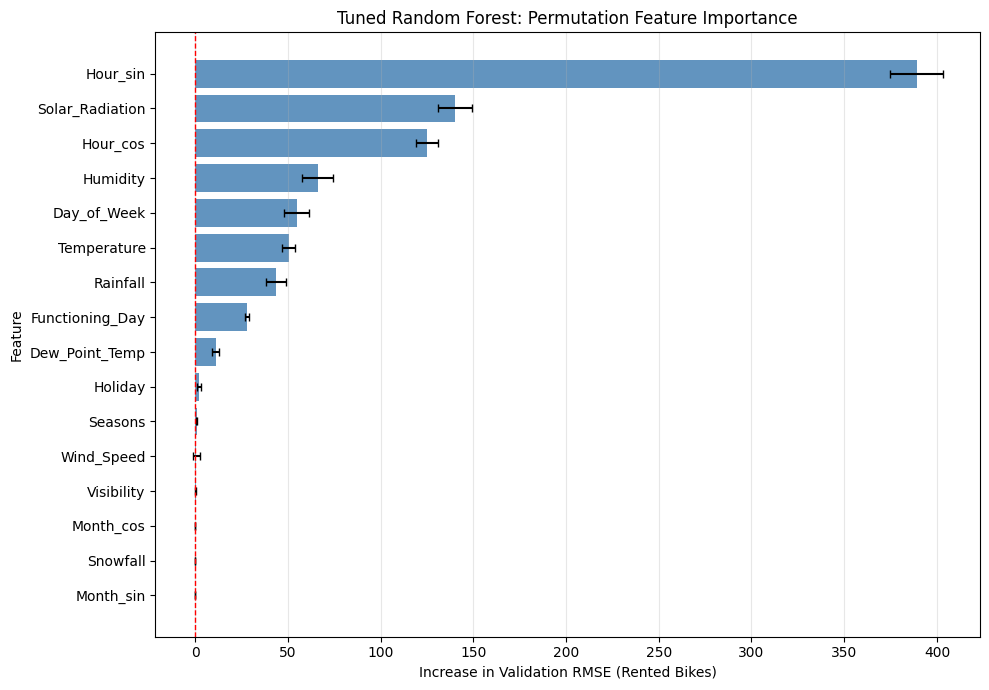

In [69]:
# Step 1: Sort features for horizontal bar chart
F1_plot_df = F1_importance_df.sort_values(
    'Importance',
    ascending=True
)

# Step 2: Plot permutation importance
plt.figure(figsize=(10, 7))

plt.barh(
    F1_plot_df['Feature'],
    F1_plot_df['Importance'],
    xerr=F1_plot_df['Std'],
    color='steelblue',
    alpha=0.85,
    capsize=3
)

plt.axvline(
    x=0,
    color='red',
    linestyle='--',
    linewidth=1
)

plt.xlabel('Increase in Validation RMSE (Rented Bikes)')
plt.ylabel('Feature')
plt.title('Tuned Random Forest: Permutation Feature Importance')
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

### F2.1. Interpretation of Correlated and Cyclical Features

Permutation Importance should be interpreted carefully when input features are correlated or represent different transformations of the same underlying variable.

For example:

- Temperature and Dew_Point_Temp may contain overlapping weather information.
- Hour_sin and Hour_cos jointly represent the cyclical structure of the hour of day.
- Month_sin and Month_cos jointly represent annual seasonality.
- Seasons and Month-derived features may contain overlapping seasonal information.

When correlated features are evaluated independently, the model may retain similar information through other predictors, potentially reducing their individual permutation importance.

In addition, independently shuffling cyclical sine and cosine features can create unrealistic combinations.

To address this issue, grouped permutation importance is used to assess the combined predictive contribution of related temporal features.

Grouped permutation importance remains an associative model diagnostic rather than evidence of causality.

In [70]:
# Step 1: Define feature groups
F2_feature_groups = {
    'Hour (Cyclical)': ['Hour_sin', 'Hour_cos'],
    'Month (Cyclical)': ['Month_sin', 'Month_cos'],
    'Weather Temperature': ['Temperature', 'Dew_Point_Temp'],
    'Operational Status': ['Functioning_Day']
}

# Step 2: Calculate baseline validation RMSE
F2_baseline_rmse = F1_val_metrics['RMSE']

F2_group_results = []
F2_rng = np.random.default_rng(42)

# Step 3: Shuffle each feature group
for group_name, columns in F2_feature_groups.items():

    F2_rmse_changes = []

    for repeat in range(10):
        F2_X_permuted = F1_X_val.copy()

        # Apply the same row permutation to every column
        F2_order = F2_rng.permutation(len(F2_X_permuted))

        F2_X_permuted[columns] = (
            F2_X_permuted[columns]
            .iloc[F2_order]
            .to_numpy()
        )

        F2_pred = F1_model.predict(F2_X_permuted)

        F2_rmse = np.sqrt(
            mean_squared_error(F1_y_val, F2_pred)
        )

        F2_rmse_changes.append(
            F2_rmse - F2_baseline_rmse
        )

    F2_group_results.append({
        'Feature Group': group_name,
        'Importance': np.mean(F2_rmse_changes),
        'Std': np.std(F2_rmse_changes)
    })

# Step 4: Display results
F2_group_df = pd.DataFrame(
    F2_group_results
).sort_values(
    'Importance',
    ascending=False
)

display(F2_group_df.round(4))

,Feature Group,Importance,Std
0,Hour (Cyclical),452.085,8.289
2,Weather Temperature,76.458,5.128
3,Operational Status,28.591,1.700
1,Month (Cyclical),-0.092,0.348


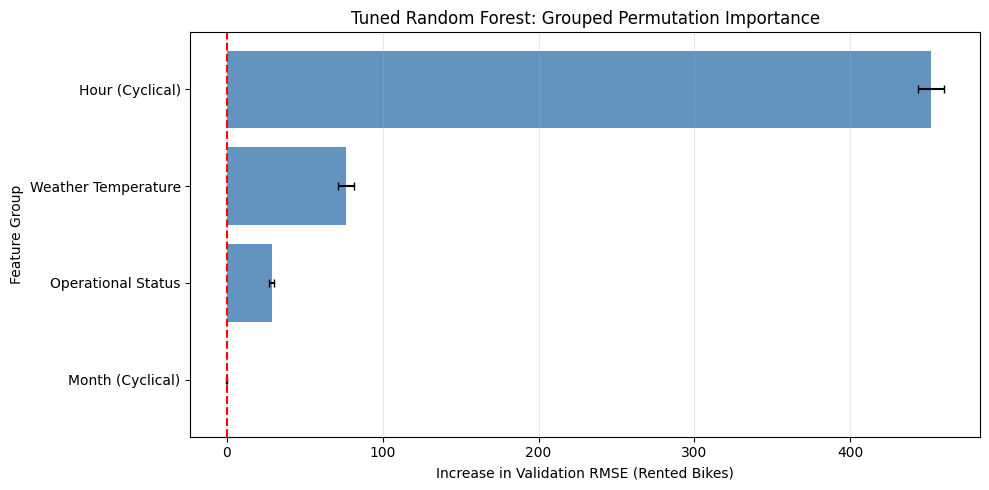

In [71]:
# Step 1: Prepare grouped importance data
F2_plot_df = F2_group_df.sort_values(
    'Importance',
    ascending=True
)

# Step 2: Plot grouped importance
plt.figure(figsize=(10, 5))

plt.barh(
    F2_plot_df['Feature Group'],
    F2_plot_df['Importance'],
    xerr=F2_plot_df['Std'],
    color='steelblue',
    alpha=0.85,
    capsize=3
)

plt.axvline(
    x=0,
    color='red',
    linestyle='--'
)

plt.xlabel('Increase in Validation RMSE (Rented Bikes)')
plt.ylabel('Feature Group')
plt.title('Tuned Random Forest: Grouped Permutation Importance')
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

### F3. Feature Importance Summary

Permutation Importance was applied to investigate which predictors contributed most strongly to the tuned Random Forest model's predictive performance.

The analysis used the final date-based chronological validation fold. A separate model was fitted using the selected hyperparameters and only the historical observations preceding the validation period.

**1. Validation Performance**

| Metric | Result |
|---|---:|
| Training Observations | 5,856 |
| Validation Observations | 1,152 |
| Validation MAE | 183.31 |
| Validation RMSE | 298.29 |
| Validation R² | 0.7869 |

The model achieved a validation R² of 0.7869, providing a basis for interpreting feature importance during this chronological validation period.

**2. Individual Permutation Importance**

Permutation Importance was calculated using the increase in validation RMSE after randomly shuffling each feature.

Each feature was shuffled 10 times, and the mean increase in RMSE was used as its importance score.

| Rank | Feature | Importance (RMSE Increase) |
|---|---|---:|
| 1 | Hour_sin | 388.97 |
| 2 | Solar_Radiation | 139.96 |
| 3 | Hour_cos | 124.89 |
| 4 | Humidity | 66.05 |
| 5 | Day_of_Week | 54.86 |
| 6 | Temperature | 50.42 |
| 7 | Rainfall | 43.65 |
| 8 | Functioning_Day | 28.18 |
| 9 | Dew_Point_Temp | 11.22 |
| 10 | Holiday | 2.31 |

**Time-of-Day Patterns**

Hour_sin and Hour_cos were among the most important individual features.

These results indicate that the model relies heavily on daily temporal patterns to predict hourly bike rental demand.

This finding is consistent with the exploratory data analysis, which identified low overnight demand and pronounced weekday commuting peaks.

Because Hour_sin and Hour_cos jointly represent the hour of day, their combined contribution was also investigated using grouped permutation importance.

**Solar Radiation**

Solar_Radiation was the second most important individual feature, with an average RMSE increase of 139.96 after permutation.

Solar radiation may provide information about daylight conditions, weather, and daily activity patterns.

However, its predictive importance should not be interpreted as evidence of a direct causal effect on rental demand.

**Weather and Weekly Patterns**

Humidity, Temperature, Rainfall, and Day_of_Week also contributed substantially to predictive performance.

These findings align with the exploratory analysis, which identified relationships between weather conditions, weekday patterns, and rental demand.

The results suggest that combining temporal and environmental information is important for accurate demand estimation.

**3. Grouped Permutation Importance**

Grouped permutation importance was applied to related predictors, including:

- Hour_sin and Hour_cos
- Month_sin and Month_cos
- Temperature and Dew_Point_Temp
- Functioning_Day

The hour-of-day group demonstrated the largest importance, substantially exceeding the other evaluated feature groups.

The temperature-related group showed the second-largest contribution, followed by operational status.

The month-related group exhibited negligible importance during the selected validation period.

These results reinforce the conclusion that daily temporal patterns are especially important for the current model.

Grouped permutation helps preserve internal relationships between related transformed features, but it does not eliminate all limitations caused by correlations among different feature groups.

**4. Low-Importance Features**

Several features demonstrated very low or near-zero individual importance, including:

- Holiday
- Seasons
- Wind_Speed
- Visibility
- Month_sin and Month_cos
- Snowfall

Low permutation importance does not necessarily indicate that a feature has no relationship with rental demand.

Potential explanations include overlapping information among predictors, limited feature variation during the validation period, and model-specific feature usage.

For example, seasonal patterns may already be partially represented by Temperature, Solar_Radiation, and other weather-related features.

Therefore, these features should not be removed solely based on their individual permutation importance scores.

**5. Interpretation Limitations**

Permutation Importance measures a trained model's reliance on predictive information rather than the causal influence of a variable.

Several limitations should be considered:

- **Correlated Predictors:** Features containing overlapping information may have reduced individual importance.
- **Validation Period:** Importance values were estimated using one chronological validation fold and may differ across other periods.
- **Temporal Dependencies:** Randomly shuffling hourly observations can disrupt realistic time-dependent relationships.
- **Model Dependence:** Importance rankings describe the fitted Random Forest rather than universal relationships within the bike-sharing system.
- **Feature Transformations:** Cyclical features should be interpreted together to assess their combined contribution.

The selected hyperparameters were previously chosen through cross-validation, including this fold. Therefore, the importance analysis is descriptive rather than an independent assessment of model-selection performance.

**6. Business Implications**

The feature importance findings suggest that accurate bike-sharing demand estimation requires particular attention to daily temporal patterns.

The strong contribution of hour-of-day features supports the importance of accounting for commuting periods and daily usage cycles when planning bike availability.

Weather-related predictors, including solar radiation, humidity, temperature, and rainfall, provide additional information that may support demand planning.

Operational status also contributes to prediction performance, highlighting the importance of incorporating known service availability when developing practical forecasting systems.

These implications are supported by predictive associations and should not be interpreted as causal effects without further investigation.

**Key Takeaways:**

- Hour-of-day features were the strongest contributors to model prediction performance.
- Hour_sin had the highest individual permutation importance (388.97 RMSE increase).
- Solar_Radiation ranked second (139.96 RMSE increase).
- Humidity, Day_of_Week, Temperature, and Rainfall were also important predictors.
- Grouped permutation confirmed the dominant contribution of cyclical hour-of-day information.
- Month-related features and several other predictors showed negligible importance during the selected validation period.
- Correlated features, temporal dependence, and validation-period characteristics limit the interpretation of permutation importance.
- Feature importance findings are consistent with the daily demand patterns and weather relationships identified during exploratory analysis.

The next section integrates exploratory analysis, model evaluation, and feature importance findings into business insights and final project conclusions.

# Part G: Business Insights & Final Conclusions

This section integrates the findings from Exploratory Data Analysis (EDA), predictive modeling, chronological cross-validation, and feature importance analysis to develop actionable business insights.

The project investigates hourly bike-sharing demand in Seoul using historical rental records, weather conditions, temporal features, and operational information.

The analysis aims to answer three business questions:

1. **Demand Patterns:** When and under what conditions is bike rental demand highest?
2. **Predictive Performance:** How accurately can machine learning models estimate hourly rental demand?
3. **Operational Implications:** How can these findings support bike availability planning and demand management?

The recommendations are based on observed associations and model diagnostics. They should be validated against operational constraints and business outcomes before implementation.

### G1. Executive Summary

This project analyzed 8,760 hourly bike-sharing observations from Seoul, covering December 2017 through November 2018, to identify demand patterns and develop predictive regression models.

The workflow included data preprocessing, exploratory analysis, feature engineering, chronological model evaluation, hyperparameter tuning, and model interpretation.

**Key Findings**

**1. Strong Daily Demand Patterns**

Hourly rental demand demonstrated clear temporal patterns. Demand peaked at approximately 18:00 overall, while the lowest demand occurred around 04:00.

Weekdays exhibited pronounced commuting-related peaks, while weekend demand was more concentrated in the afternoon.

**2. Weather and Seasonal Associations**

Rental demand varied substantially with weather conditions and seasons.

Summer recorded the highest average hourly demand (1,034.07 rentals), compared with 225.54 rentals in winter.

Hours with recorded rainfall had substantially lower average demand (163.46 rentals) than hours without rainfall (739.31 rentals).

These differences are observational associations and should not be interpreted as causal effects.

**3. Predictive Modeling Performance**

Three regression models were evaluated on a held-out chronological testing dataset.

| Model | Test MAE | Test RMSE | Test R² |
|---|---:|---:|---:|
| Linear Regression | 306.48 | 426.22 | 0.5171 |
| Baseline Random Forest | 264.16 | 361.82 | 0.6520 |
| Tuned Random Forest | 269.13 | 357.57 | 0.6601 |

Random Forest substantially outperformed Linear Regression.

The tuned Random Forest achieved the lowest test RMSE and highest test R², although the baseline Random Forest achieved a slightly lower MAE.

Hyperparameter tuning produced only modest overall improvements, highlighting the importance of rigorous validation and model selection.

**4. Feature Importance**

Permutation Importance identified hour-of-day information as the strongest predictor group for the tuned Random Forest during the selected chronological validation period.

Solar radiation, humidity, day of week, temperature, and rainfall also contributed to predictive performance.

**5. Operational Opportunities**

The findings suggest opportunities to support demand-aware bike allocation, weather-responsive planning, and operational availability management.

However, the models predict system-wide hourly rental counts rather than demand at individual stations. Station-level allocation decisions would require additional geographic and inventory data.

**Overall Conclusion**

The analysis demonstrates that combining temporal, environmental, and operational information can support hourly bike-sharing demand estimation.

The project also highlights the importance of chronological validation, interpretable modeling, and translating predictive results into business-relevant insights.

### G2. Key Business Insights

#### Insight 1: Hourly Demand Patterns Support Time-Based Capacity Planning

The exploratory analysis identified clear daily demand cycles:

- Overall peak rental demand occurred around 18:00.
- The lowest demand occurred around 04:00.
- Weekday demand featured morning and evening commuting peaks.
- Weekend demand increased more gradually toward the afternoon.

Average hourly rental demand was approximately 719.45 on weekdays and 667.34 on weekends, representing a 7.24% lower average on weekends.

Permutation Importance also identified hour-of-day information as the strongest predictor group for the tuned Random Forest during the selected validation period.

**Business Implication:**

Bike-sharing operators could use historical hourly demand patterns to inform staffing, maintenance schedules, and system-wide capacity planning.

For example, maintenance activities that temporarily reduce available bike capacity may be more practical during historically low-demand periods, subject to operational requirements.

#### Insight 2: Weather Conditions Are Associated with Demand Changes

Weather-related variables demonstrated meaningful associations with bike rentals.

Hours with rainfall recorded an average of 163.46 rentals, compared with 739.31 rentals during hours without rainfall.

Temperature was positively correlated with rental demand in the historical dataset, although exploratory analysis indicated a nonlinear relationship.

Humidity, solar radiation, and rainfall also contributed to the model's predictive performance.

**Business Implication:**

Weather forecasts could be incorporated into short-term demand planning to anticipate changes in expected rental activity.

However, actual weather observations should be replaced with forecast information when developing a model intended for future predictions.

#### Insight 3: Seasonal Demand Differences Affect Capacity Requirements

Average hourly rental demand varied substantially across seasons:

| Season | Average Hourly Rentals |
|---|---:|
| Winter | 225.54 |
| Spring | 730.03 |
| Summer | 1,034.07 |
| Autumn | 819.60 |

Summer demand was approximately 4.59 times higher than winter demand.

These findings suggest that seasonal demand patterns may be relevant to staffing, maintenance planning, and system-wide fleet capacity.

However, seasonal differences observed in one year may not generalize to subsequent years.

#### Insight 4: Operational Status Is Important for Prediction Consistency

All 223 zero-demand observations in the held-out testing dataset occurred during non-operational periods.

Both Random Forest models reduced zero-demand prediction error compared with Linear Regression, but still produced nonzero estimates during some periods when the system was not functioning.

**Business Implication:**

If operational status is known in advance, prediction systems can explicitly enforce zero rental demand during non-operational periods.

Such rules could improve the consistency of operational forecasts without relying exclusively on statistical model predictions.

#### Insight 5: Predictive Accuracy Varies Across Demand Conditions

Although the tuned Random Forest achieved the lowest overall testing RMSE, it did not outperform the baseline Random Forest in every scenario.

The baseline Random Forest achieved lower overall MAE and lower MAE for high-demand and zero-demand observations.

**Business Implication:**

Model selection should be aligned with the operational cost of prediction errors.

For example, underestimating a high-demand period may have different consequences from overestimating demand during a low-demand period.

A deployment-oriented evaluation would therefore benefit from business-specific error metrics and cost assumptions.

### G3. Business Recommendations

Based on the exploratory analysis, predictive modeling, and feature importance findings, several operational recommendations are proposed.

| Priority | Recommendation | Supporting Evidence | Potential Application |
|---|---|---|---|
| High | Time-based demand planning | Strong hourly demand cycles and high hour-of-day feature importance | Plan capacity around expected daily demand peaks |
| High | Weather-responsive forecasting | Rental demand differs substantially across weather conditions | Incorporate weather forecasts into short-term planning |
| Medium | Seasonal capacity planning | Summer average demand was 4.59 times winter demand | Inform seasonal staffing and fleet availability decisions |
| Medium | Operational-rule integration | All observed zero-demand test cases occurred during non-operational periods | Enforce zero predictions when service closure is known |
| Medium | Demand-specific model monitoring | Prediction errors vary across high-demand and zero-demand conditions | Monitor performance beyond overall MAE and RMSE |

**Recommendation 1: Implement Time-Aware Demand Planning**

Use hourly demand forecasts to identify periods of expected high and low rental activity.

Capacity planning and maintenance schedules could be adjusted based on recurring daily demand patterns.

Since the current dataset provides system-wide rental counts, station-level rebalancing would require additional station-level demand and inventory information.

**Recommendation 2: Incorporate Weather Forecasts**

Integrate forecasted temperature, precipitation, and other relevant weather variables into short-term rental demand estimation.

The model should be evaluated using weather information available at the time of prediction rather than actual future weather observations.

**Recommendation 3: Plan for Seasonal Demand Variation**

Use historical seasonal patterns to support longer-term planning for fleet availability, staffing, and maintenance.

Because the dataset covers only one year, additional historical observations should be collected before establishing recurring seasonal operating policies.

**Recommendation 4: Apply Known Operational Constraints**

When future service availability is known, operational rules could be applied to ensure that predicted rentals are zero during scheduled closures.

This approach should be evaluated separately from the statistical model and validated using additional unseen periods.

**Recommendation 5: Define Business-Oriented Evaluation Metrics**

Model monitoring should consider not only MAE, RMSE, and R², but also prediction errors during operationally important conditions.

Potential measures include:

- Peak-demand underprediction.
- Forecast accuracy during normal operating hours.
- Prediction bias across different weather conditions.
- Performance stability across seasons.

These metrics would help align model development with practical business objectives.

### G4. Limitations and Future Improvements

Despite the insights generated by this project, several limitations should be considered.

**1. Limited Historical Coverage**

The dataset contains approximately one year of hourly observations, covering December 2017 through November 2018.

This limits the ability to assess long-term changes in user behavior, seasonal stability, and year-over-year demand patterns.

Future work should incorporate multiple years of data to evaluate seasonal consistency and improve model generalization.

**2. Temporal Generalization**

Chronological cross-validation revealed substantial variation in predictive performance across different validation periods.

The tuned Random Forest achieved a mean cross-validation R² of 0.6012 before tuning and showed only a modest improvement in mean RMSE after hyperparameter optimization.

The final testing R² was 0.6601, indicating that a substantial portion of hourly demand variation remained unexplained.

Additional historical data and validation across multiple years would support a more comprehensive assessment of model stability.

**3. Forecast Input Availability**

The models use weather conditions and operational status as predictors.

In real-world forecasting, actual future weather conditions are not available at prediction time.

A production-oriented system would require weather forecasts and known operational schedules, followed by evaluation under realistic forecasting conditions.

**4. System-Wide Rather Than Station-Level Demand**

The dataset contains aggregated hourly rental counts rather than individual station-level demand and inventory information.

As a result, the model cannot directly determine where bikes should be relocated or how many bikes should be allocated to specific stations.

Station-level records would be required for geographic demand forecasting and fleet rebalancing optimization.

**5. Prediction Bias and Extreme-Demand Errors**

Residual analysis identified systematic underprediction in the tuned Random Forest, with a mean residual of +136.44 rentals.

Both Random Forest models also demonstrated substantial errors during some high-demand conditions.

Additional analysis of prediction bias, high-demand observations, and demand-specific error costs could help improve operational reliability.

**6. Correlated Predictors and Model Interpretability**

Permutation Importance identified strong predictive contributions from temporal and weather-related features.

However, correlated variables and cyclical feature transformations complicate the interpretation of individual importance scores.

Importance rankings describe model reliance on predictors and do not establish causal relationships.

**7. No Operational Cost Validation**

The project evaluates statistical prediction accuracy but does not measure operational costs, lost rentals, staffing efficiency, or customer satisfaction.

Consequently, the proposed recommendations represent potential applications rather than demonstrated financial benefits.

Future work should connect demand prediction errors with operational outcomes to assess business value.

**Future Improvements**

Future development could focus on:

- Collecting multiple years of historical rental data.
- Integrating actual weather forecasts and known operating schedules.
- Developing station-level demand forecasting models.
- Evaluating historical-demand lag features under leakage-safe chronological validation.
- Investigating systematic prediction bias.
- Testing operational rules using additional unseen data.
- Measuring business outcomes using cost-sensitive evaluation metrics.

### G5. Final Project Conclusion

This project developed an end-to-end analytical workflow for understanding and predicting hourly bike-sharing demand in Seoul.

The analysis combined data preprocessing, exploratory data analysis, temporal feature engineering, regression modeling, chronological cross-validation, hyperparameter optimization, and feature interpretation.

Exploratory analysis revealed strong daily demand cycles, substantial seasonal variation, and meaningful associations between weather conditions and rental activity.

Three regression models were evaluated using a chronological holdout dataset. Random Forest substantially outperformed Linear Regression, demonstrating the value of nonlinear modeling.

The tuned Random Forest achieved the highest test R² of **0.6601** and the lowest test RMSE of **357.57**, while the baseline Random Forest achieved the lowest test MAE of **264.16**.

Hyperparameter tuning produced only modest performance improvements, and the analysis revealed continuing challenges related to generalization, extreme-demand prediction, and systematic underestimation.

Permutation Importance identified hour-of-day information as the strongest predictor group during the selected chronological validation period, followed by contributions from weather-related and weekly temporal features.

From a business perspective, the findings suggest opportunities to support time-aware demand planning, weather-responsive forecasting, and operational availability management.

However, practical deployment would require additional historical data, realistic forecast inputs, station-level information, and operational cost evaluation.

**Overall, the project demonstrates how statistical analysis and machine learning can be combined to generate predictive insights while maintaining attention to model validation, interpretability, and business relevance.**

In [72]:
# Step 1: Build final project scorecard
G_model_scorecard = E_model_comparison.copy()

# Step 2: Rank models by evaluation metric
G_model_scorecard['MAE Rank'] = (
    G_model_scorecard['MAE'].rank(ascending=True).astype(int)
)

G_model_scorecard['RMSE Rank'] = (
    G_model_scorecard['RMSE'].rank(ascending=True).astype(int)
)

G_model_scorecard['R2 Rank'] = (
    G_model_scorecard['R2'].rank(ascending=False).astype(int)
)

# Step 3: Display final scorecard
display(G_model_scorecard.round(4))

# Step 4: Report metric leaders
print('Final Project Model Leaders:')
print(f'Lowest MAE:  {E_model_comparison["MAE"].idxmin()}')
print(f'Lowest RMSE: {E_model_comparison["RMSE"].idxmin()}')
print(f'Highest R²:  {E_model_comparison["R2"].idxmax()}')

,MAE,RMSE,R2,MAE Rank,RMSE Rank,R2 Rank
Linear Regression,306.478,426.215,0.517,3,3,3
Baseline Random Forest,264.164,361.818,0.652,1,2,2
Tuned Random Forest,269.129,357.568,0.660,2,1,1


Final Project Model Leaders:
Lowest MAE:  Baseline Random Forest
Lowest RMSE: Tuned Random Forest
Highest R²:  Tuned Random Forest
